# Visualize ANN Benchmark Results

Figures for the four configs (`vit-coco`, `resnet-coco`, `vit-zappos`, `resnet-zappos`).
Every figure is saved to `media/`.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter, LogLocator

# Configurations to include (keys from datasets.py).
CONFIG_KEYS = ["vit-coco", "resnet-coco", "vit-zappos", "resnet-zappos"]

SAVE_FIGURES = True   # write every figure to media/
FIG_DPI = 300

In [2]:
# Find this experiment folder whether the notebook runs from its own
# folder or from the repository root, then reuse the shared registry.
EXPERIMENT_DIR = Path.cwd()
if not (EXPERIMENT_DIR / "datasets.py").exists():
    EXPERIMENT_DIR = Path.cwd() / "experiments" / "ann-comparison"
sys.path.insert(0, str(EXPERIMENT_DIR))
from datasets import CONFIGS, DATASETS, MODELS, REPO_ROOT, results_dir

MEDIA_DIR = REPO_ROOT / "media"
MEDIA_DIR.mkdir(exist_ok=True)

# Search parameter swept by each method (Exact FlatIP has none).
SWEEP_PARAM = {"LSH": "nbits", "IVF-Flat": "nprobe", "IVF-PQ": "nprobe",
               "HNSW": "efSearch", "HNSW-PQ": "efSearch"}

meta_rows, result_rows = [], []
for key in CONFIG_KEYS:
    path = results_dir(key) / "ann_results.json"
    if not path.exists():
        print(f"{key}: no ann_results.json - run benchmark_ann.py --config {key}")
        continue
    data = json.loads(path.read_text())
    meta_rows.append({"config": key, **data["metadata"]})
    for r in data["results"]:
        param = SWEEP_PARAM.get(r["algorithm"])
        result_rows.append({
            "config": key,
            "label": CONFIGS[key]["label"],
            "model": CONFIGS[key]["model"],
            "dataset": CONFIGS[key]["dataset"],
            "algorithm": r["algorithm"],
            "param_name": param,
            "param_value": r["parameters"][param] if param else np.nan,
            "setting": f"{param}={r['parameters'][param]}" if param else "-",
            **{k: v for k, v in r.items() if k not in ("algorithm", "parameters")},
        })

# meta: one row per configuration. results: one row per (config, method, setting).
meta = pd.DataFrame(meta_rows).set_index("config")
results = pd.DataFrame(result_rows)
results["model_label"] = results["model"].map(lambda m: MODELS[m]["label"])
results["dataset_label"] = results["dataset"].map(lambda d: DATASETS[d]["label"])

# Relative to exact search in the same configuration (raw latencies are not
# comparable across configs: gallery size and dimension differ).
exact = results[results["algorithm"] == "Exact FlatIP"].set_index("config")
results["speedup"] = results["config"].map(exact["latency_ms_per_query"]) / results["latency_ms_per_query"]
results["compression"] = results["config"].map(exact["index_size_mb"]) / results["index_size_mb"]

# Corruption robustness summaries (optional, from pipeline/corruption.py).
corruption_frames = []
for key in meta.index:
    path = results_dir(key) / "robustness" / "corruption_summary.csv"
    if path.exists():
        corruption_frames.append(pd.read_csv(path).assign(
            config=key, model=CONFIGS[key]["model"], dataset=CONFIGS[key]["dataset"]))
corruption = pd.concat(corruption_frames, ignore_index=True) if corruption_frames else None

display(meta[["label", "gallery_size", "num_queries", "dimension"]])
print(f"results: {len(results)} rows x {results.shape[1]} columns")
print(f"corruption results: {'none' if corruption is None else ', '.join(corruption['config'].unique())}")
print(f"figures -> {MEDIA_DIR}")

,label,gallery_size,num_queries,dimension
config,,,,
vit-coco,ViT-B/16 / COCO,122403,1000,768
resnet-coco,ResNet18 / COCO,122403,1000,512
vit-zappos,ViT-B/16 / Zappos,49025,1000,768
resnet-zappos,ResNet18 / Zappos,49025,1000,512


results: 116 rows x 26 columns
corruption results: vit-coco, resnet-coco, vit-zappos, resnet-zappos
figures -> C:\Users\iamgr\Desktop\SC4020-Lab1\media


In [3]:
results.head()

,config,label,model,dataset,algorithm,param_name,param_value,setting,build_seconds,search_seconds,...,precision_at_5,precision_at_10,precision_at_20,map_at_5,map_at_10,map_at_20,model_label,dataset_label,speedup,compression
0,vit-coco,ViT-B/16 / COCO,vit,coco,Exact FlatIP,NaN,NaN,-,0.044534,1.412327,...,1.0000,1.0000,1.00000,1.000000,1.000000,1.000000,ViT-B/16,COCO,1.000000,1.000000
1,vit-coco,ViT-B/16 / COCO,vit,coco,LSH,nbits,64.0,nbits=64,0.139117,0.082793,...,0.0766,0.0957,0.11090,0.044587,0.046438,0.047513,ViT-B/16,COCO,17.058485,319.767044
2,vit-coco,ViT-B/16 / COCO,vit,coco,LSH,nbits,128.0,nbits=128,0.227181,0.087697,...,0.1684,0.1910,0.21870,0.115527,0.113127,0.120141,ViT-B/16,COCO,16.104599,159.889844
3,vit-coco,ViT-B/16 / COCO,vit,coco,LSH,nbits,256.0,nbits=256,0.434947,0.146073,...,0.2902,0.3240,0.36155,0.214850,0.222056,0.240122,ViT-B/16,COCO,9.668636,79.946503
4,vit-coco,ViT-B/16 / COCO,vit,coco,LSH,nbits,512.0,nbits=512,0.818353,0.330887,...,0.4430,0.4734,0.50940,0.361090,0.374085,0.399059,ViT-B/16,COCO,4.268307,39.973647


In [4]:
# Shared helpers and styling, reused by every figure below.
METHOD_COLORS = {
    "Exact FlatIP": "tab:gray",
    "LSH": "tab:green",
    "IVF-Flat": "tab:red",
    "IVF-PQ": "tab:orange",
    "HNSW": "tab:blue",
    "HNSW-PQ": "tab:purple",
}
METHOD_ORDER = list(METHOD_COLORS)


def save_figure(fig, name):
    # Save to media/<name>.png when SAVE_FIGURES is on.
    if not SAVE_FIGURES:
        return
    path = MEDIA_DIR / f"{name}.png"
    fig.savefig(path, dpi=FIG_DPI, bbox_inches="tight", pad_inches=0.05)
    print(f"saved {path.relative_to(REPO_ROOT)}")


def legend_above(fig, ax, fontsize=8):
    # Horizontal legend centered above the figure, directly below the
    # suptitle: title -> legend -> panels, tightly stacked. The suptitle
    # must be set before this call.
    handles, labels = ax.get_legend_handles_labels()
    if not handles:
        return
    fig.canvas.draw()   # measure the suptitle first
    renderer = fig.canvas.get_renderer()
    top = 0.955
    if fig._suptitle is not None:
        top = fig._suptitle.get_window_extent(renderer).y0 / fig.bbox.height - 0.008
    legend = fig.legend(handles, labels, loc="upper center", ncol=len(handles),
                        frameon=False, fontsize=fontsize, bbox_to_anchor=(0.5, top))
    fig.tight_layout()   # optimise margins (reserves suptitle space)
    fig.canvas.draw()    # measure the real legend height
    renderer = fig.canvas.get_renderer()
    legend_bottom = legend.get_window_extent(renderer).y0 / fig.bbox.height
    grid_top = max(a.get_tightbbox(renderer).y1 for a in fig.axes) / fig.bbox.height
    patch_top = max(a.get_window_extent(renderer).y1 for a in fig.axes) / fig.bbox.height
    title_band = grid_top - patch_top   # panel titles above the axes patches
    fig.subplots_adjust(top=legend_bottom - 0.01 - title_band)   # lift the grid below the legend


def pick(algorithm, param_value=None, data=None):
    # Rows of one method (optionally one setting) across all configurations,
    # from `data` (default: the main `results`).
    source = results if data is None else data
    sub = source[source["algorithm"] == algorithm]
    if param_value is not None:
        sub = sub[sub["param_value"] == param_value]
    return sub


# One colour per experiment (model x dataset), shared by every per-config chart.
CONFIG_COLORS = {
    "vit-coco": "tab:blue",
    "resnet-coco": "tab:orange",
    "vit-zappos": "tab:green",
    "resnet-zappos": "tab:red",
}

# (column, display label) for every retrieval accuracy metric.
ACCURACY_METRICS = [
    (f"{metric}_at_{k}", f"{label}@{k}")
    for metric, label in [("recall", "Recall"), ("map", "mAP")]
    for k in (5, 10, 20)
]


def plot_sweep(ax, algorithm, metric, ylabel, ylim=(0, 1), yscale="linear",
               data=None, reference=None):
    # One line per configuration in `data` (default `results`): `metric` against
    # the method's swept parameter. `reference` (a frame indexed by config) adds
    # a dashed line per configuration in the same colour. `ylim=None` leaves the
    # value axis range to matplotlib.
    sub = pick(algorithm, data=data)
    for config in meta.index:
        rows = sub[sub["config"] == config].sort_values("param_value")
        if rows.empty:
            continue
        ax.plot(rows["param_value"], rows[metric], marker="o",
                color=CONFIG_COLORS[config], label=meta.loc[config, "label"])
        if reference is not None and config in reference.index:
            ax.axhline(reference.loc[config, metric], ls="--", lw=1,
                       color=CONFIG_COLORS[config], alpha=0.6)
    values = sorted(sub["param_value"].unique())
    ax.set_xscale("log", base=2)
    ax.set_yscale(yscale)
    ax.set_xticks(values, [f"{v:g}" for v in values])
    ax.minorticks_off()
    ax.set_xlabel(sub["param_name"].iloc[0])
    ax.set_ylabel(ylabel)
    if ylim is not None:
        ax.set_ylim(*ylim)
    ax.grid(alpha=0.3)


def add_reference_legend(ax, reference_label):
    # Legend entry for the dashed reference lines (one per configuration colour).
    if reference_label:
        ax.plot([], [], ls="--", color="gray", label=f"{reference_label} (dashed)")


def accuracy_figures(algorithm, file_prefix, ylim=(0, 1), data=None,
                     reference=None, reference_label=None):
    # One figure per accuracy metric -> media/<file_prefix>_<metric>.png (saved,
    # not shown), then all metrics in one grid, the only figure displayed
    # (rows Recall / mAP, columns @5 / @10 / @20) -> media/<file_prefix>_accuracy_grid.png.
    # `ylim` zooms the score axis when every value sits in a narrow band;
    # `data` / `reference` / `reference_label` as in plot_sweep.
    param = pick(algorithm, data=data)["param_name"].iloc[0]
    for metric, label in ACCURACY_METRICS:
        fig, ax = plt.subplots(figsize=(6, 4))
        plot_sweep(ax, algorithm, metric, label, ylim, data=data, reference=reference)
        add_reference_legend(ax, reference_label)
        fig.suptitle(f"{algorithm}: {label} vs {param}", fontsize=12)
        legend_above(fig, ax, fontsize=7)
        save_figure(fig, f"{file_prefix}_{metric}")
        plt.close(fig)   # saved only; the grid below shows them all

    fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True, sharey=True)
    for ax, (metric, label) in zip(axes.ravel(), ACCURACY_METRICS):
        plot_sweep(ax, algorithm, metric, label, ylim, data=data, reference=reference)
        ax.set_title(label)
        ax.label_outer()   # axis labels only on the outer panels
    for ax, row_label in zip(axes[:, 0], ["Recall", "mAP"]):
        ax.set_ylabel(row_label)
    add_reference_legend(axes[0, 0], reference_label)
    fig.suptitle(f"{algorithm}: Retrieval Accuracy vs {param}", fontsize=14)
    legend_above(fig, axes[0, 0])
    save_figure(fig, f"{file_prefix}_accuracy_grid")
    plt.show()


# (column, display label, file suffix) for speed and memory.
COST_METRICS = [
    ("latency_ms_per_query", "Latency (ms/query)", "latency"),
    ("index_size_mb", "Index Size (MB)", "index_size"),
    ("build_seconds", "Build Time (s)", "build_time"),
]


def cost_figure(algorithm, file_prefix, suffix, data=None, reference=None,
                reference_label="Exact FlatIP"):
    # One cost metric from COST_METRICS (by its suffix: "latency", "index_size"
    # or "build_time")
    # against the swept parameter -> media/<file_prefix>_<suffix>.png. Log value
    # axis; each dashed line is `reference` (default Exact FlatIP) in the
    # configuration of the same colour.
    metric, label = next((m, l) for m, l, s in COST_METRICS if s == suffix)
    param = pick(algorithm, data=data)["param_name"].iloc[0]
    if reference is None:
        reference = pick("Exact FlatIP").set_index("config")
    fig, ax = plt.subplots(figsize=(6, 4))
    plot_sweep(ax, algorithm, metric, label, ylim=None, yscale="log",
               data=data, reference=reference)
    # Narrow ranges (flat lines) need a tick at every 1-9 x 10^k.
    low, high = ax.get_ylim()
    subs = range(1, 10) if high / low < 10 else (1, 2, 5)
    ax.yaxis.set_major_locator(LogLocator(subs=subs))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
    add_reference_legend(ax, reference_label)
    fig.suptitle(f"{algorithm}: {label} vs {param}", fontsize=12)
    legend_above(fig, ax, fontsize=7)
    save_figure(fig, f"{file_prefix}_{suffix}")
    plt.show()

## Query and answers

One query per dataset and its exact top-5 answers in each config (number = cosine similarity).

In [5]:
# The clean query's exact top-5 answers come from the corruption run's local
# cache (no FAISS recomputation); the gallery mapping is reproduced from
# ann_results.json exactly as pipeline/corruption.py built it (same seed).
from PIL import Image

K_ANSWERS = 5   # answers shown per row
GRID_KEYS = ["vit-coco", "resnet-coco", "vit-zappos", "resnet-zappos"]

def load_image_info(dataset):
    # COCO filenames are
    # 12-digit zero-padded ids; Zappos ids index the sorted image paths.
    image_dir = DATASETS[dataset]["image_dir"]
    if not image_dir.exists():
        return None
    if dataset == "coco":
        return {"path": lambda image_id: image_dir / f"{int(image_id):012d}.jpg",
                "label": lambda image_id: ""}
    paths = sorted(image_dir.rglob("*.jpg"), key=lambda p: str(p))
    categories = np.array([p.relative_to(image_dir).parts[0] for p in paths])
    subcategories = np.array([p.relative_to(image_dir).parts[1] for p in paths])
    return {"path": lambda image_id: paths[int(image_id)],
            "label": lambda image_id: f"{categories[image_id]} / {subcategories[image_id]}"}

image_info = {d: load_image_info(d) for d in ("coco", "zappos")}

rows = []
for key in GRID_KEYS:
    dataset = CONFIGS[key]["dataset"]
    info = image_info[dataset]
    rob = results_dir(key) / "robustness"
    if info is None or not (rob / "corrupted_query_clean_top20.npy").exists():
        print(f"{meta.loc[key, 'label']}: skipped - needs the images and the local "
              f"corruption cache (re-run pipeline/corruption.py)")
        continue
    bench = json.loads((results_dir(key) / "ann_results.json").read_text())["metadata"]
    gallery_rows = np.sort(np.random.default_rng(bench["seed"])
                           .permutation(bench["dataset_size"])[bench["num_queries"]:])
    params = json.loads((rob / "corruption_params.json").read_text())
    query_row = int(params["query_rows"][0])   # first corruption query
    ids = np.load(CONFIGS[key]["ids"])
    embeddings = np.load(CONFIGS[key]["emb"], mmap_mode="r")

    query_id = int(ids[query_row])
    top = np.load(rob / "corrupted_query_clean_top20.npy")[0, :K_ANSWERS]
    query_vector = np.asarray(embeddings[query_row])
    answers = []
    for gallery_row in top:
        answer_id = int(ids[gallery_rows[int(gallery_row)]])
        vector = np.asarray(embeddings[int(gallery_rows[int(gallery_row)])])
        answers.append({"id": answer_id, "score": float(query_vector @ vector)})
    rows.append({"key": key, "query_id": query_id, "answers": answers})

if not rows:
    print("Query-and-answers grid skipped: no configuration has the images and a "
          "local corruption cache.")
else:
    fig, axes = plt.subplots(len(rows), K_ANSWERS + 1,
                             figsize=(2.4 * (K_ANSWERS + 1), 3.0 * len(rows)))
    for r, row in enumerate(rows):
        key = row["key"]
        info = image_info[CONFIGS[key]["dataset"]]
        ax = axes[r][0]
        ax.imshow(Image.open(info["path"](row["query_id"])).convert("RGB"))
        ax.set_title(f"{meta.loc[key, 'label']}\nquery {row['query_id']}", fontsize=8)
        ax.axis("off")
        for c, answer in enumerate(row["answers"]):
            ax = axes[r][c + 1]
            ax.imshow(Image.open(info["path"](answer["id"])).convert("RGB"))
            title = f"#{c + 1}  cos {answer['score']:.3f}"
            label = info["label"](answer["id"])
            if label:
                title += f"\n{label}"
            title += f"\nid {answer['id']}"
            ax.set_title(title, fontsize=7)
            ax.axis("off")
    fig.suptitle("Query and its exact top-5 answers: the same query per dataset, both models")
    fig.tight_layout()
    save_figure(fig, "query_answers_grid")
    plt.show()

ViT-B/16 / COCO: skipped - needs the images and the local corruption cache (re-run pipeline/corruption.py)
ResNet18 / COCO: skipped - needs the images and the local corruption cache (re-run pipeline/corruption.py)
ViT-B/16 / Zappos: skipped - needs the images and the local corruption cache (re-run pipeline/corruption.py)
ResNet18 / Zappos: skipped - needs the images and the local corruption cache (re-run pipeline/corruption.py)
Query-and-answers grid skipped: no configuration has the images and a local corruption cache.


## Visualizations

- **Accuracy**: Recall@K and mAP@K against the exact top-K of the same config.
  Precision@K is left out because it always equals Recall@K here.
- **Speed** (ms/query) and **memory** (MB) use a log scale; dashed line = exact search.

## LSH (nbits)

`nbits`: length of the binary hash code.

### LSH: accuracy

saved media\lsh_recall_at_5.png
saved media\lsh_recall_at_10.png
saved media\lsh_recall_at_20.png
saved media\lsh_map_at_5.png
saved media\lsh_map_at_10.png
saved media\lsh_map_at_20.png
saved media\lsh_accuracy_grid.png


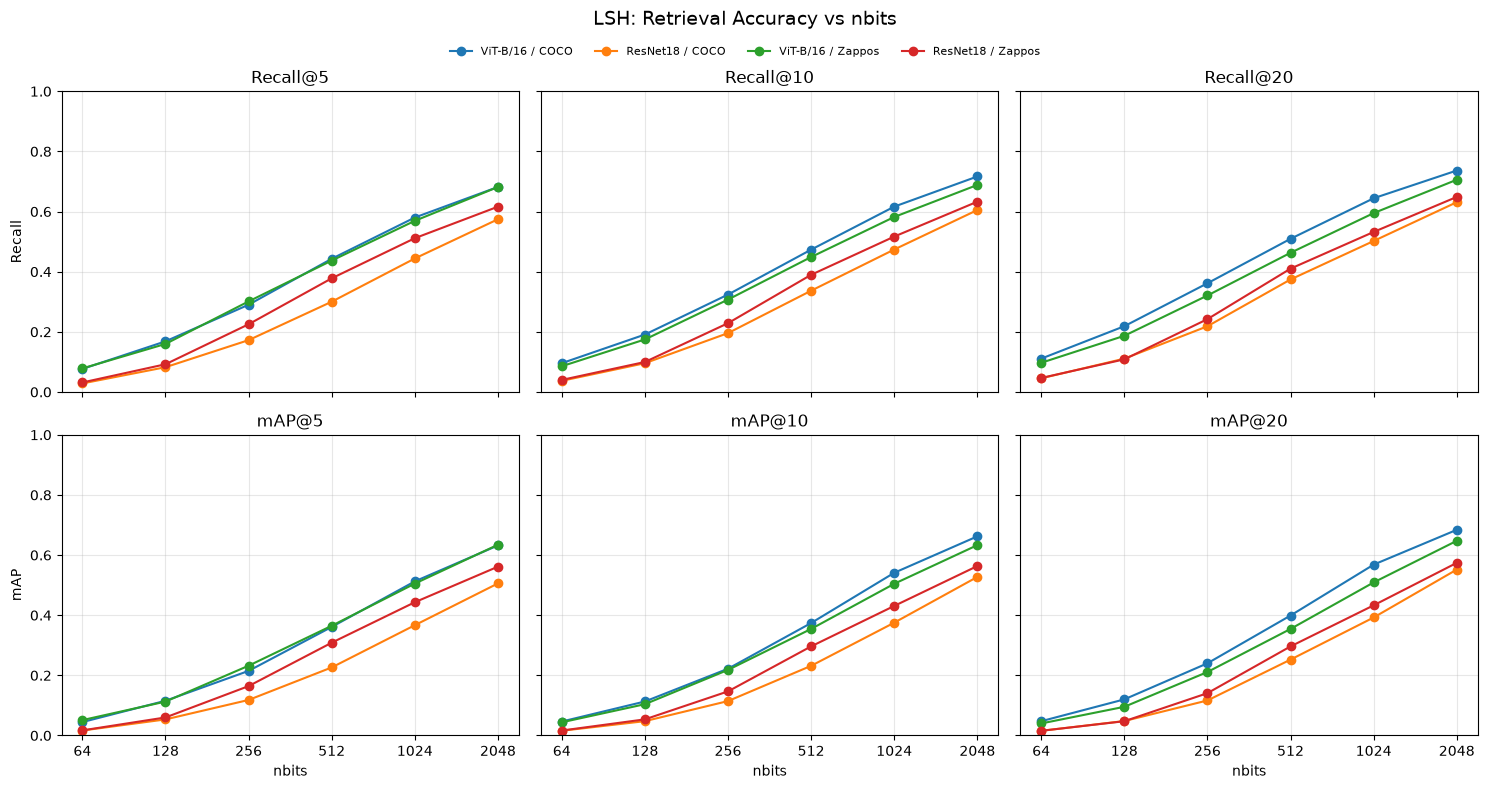

In [6]:
accuracy_figures("LSH", "lsh")

### LSH: speed

saved media\lsh_latency.png


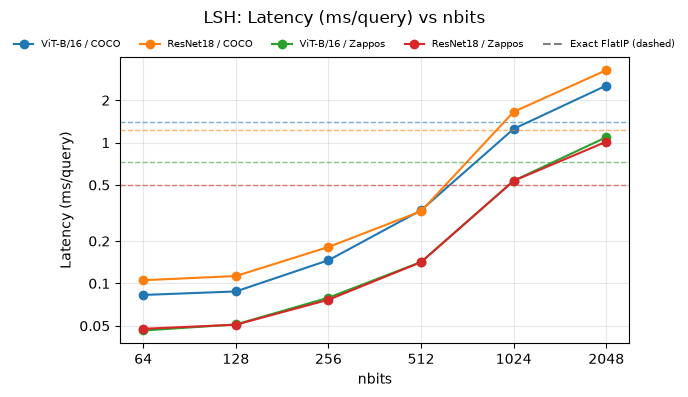

In [7]:
cost_figure("LSH", "lsh", "latency")

### LSH: memory

saved media\lsh_index_size.png


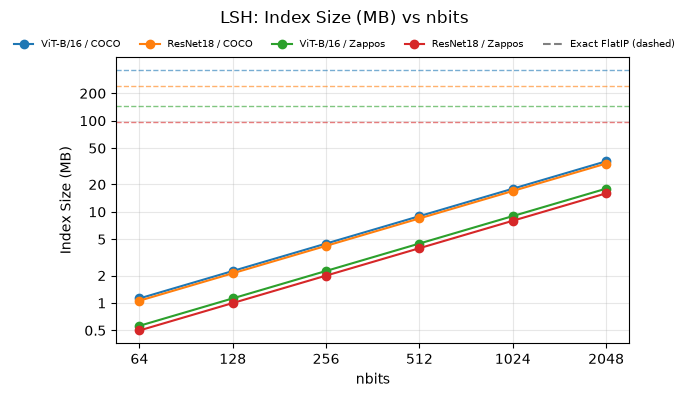

In [8]:
cost_figure("LSH", "lsh", "index_size")

## IVF-Flat (nprobe)

`nprobe`: number of the 256 clusters searched per query.

### IVF-Flat: accuracy

saved media\ivfflat_recall_at_5.png
saved media\ivfflat_recall_at_10.png
saved media\ivfflat_recall_at_20.png
saved media\ivfflat_map_at_5.png
saved media\ivfflat_map_at_10.png
saved media\ivfflat_map_at_20.png
saved media\ivfflat_accuracy_grid.png


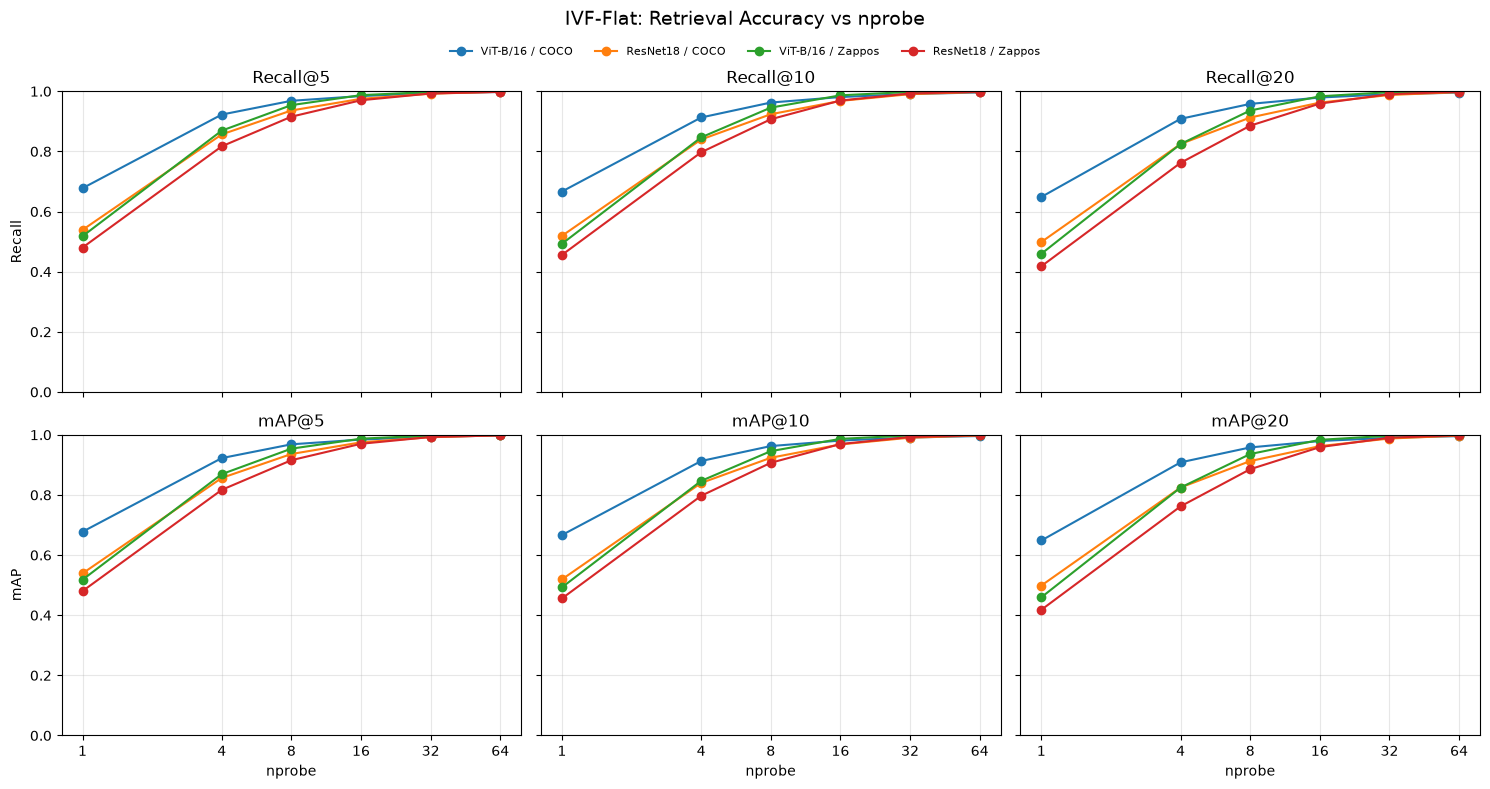

In [9]:
accuracy_figures("IVF-Flat", "ivfflat")

### IVF-Flat: speed

saved media\ivfflat_latency.png


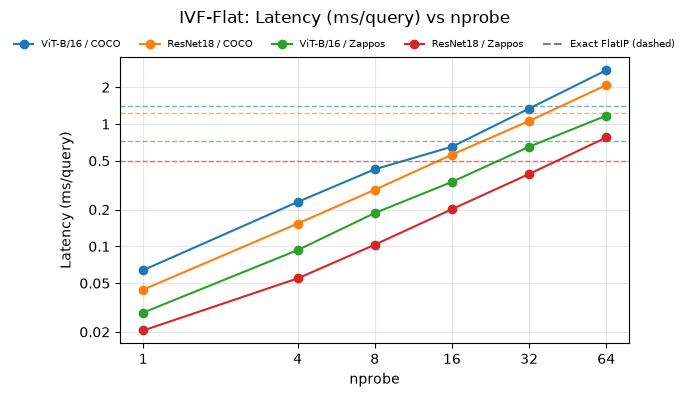

In [10]:
cost_figure("IVF-Flat", "ivfflat", "latency")

### IVF-Flat: memory

saved media\ivfflat_index_size.png


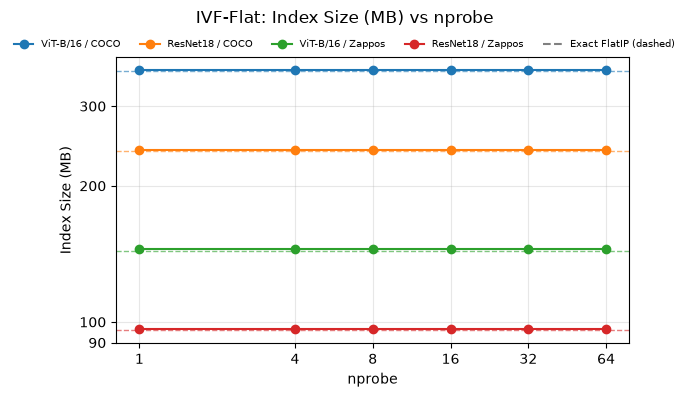

In [11]:
cost_figure("IVF-Flat", "ivfflat", "index_size")

## IVF-PQ (nprobe)

IVF-Flat with PQ-compressed vectors (`m` = 48 for ViT, 32 for ResNet18).

### IVF-PQ: accuracy

saved media\ivfpq_recall_at_5.png
saved media\ivfpq_recall_at_10.png
saved media\ivfpq_recall_at_20.png
saved media\ivfpq_map_at_5.png
saved media\ivfpq_map_at_10.png
saved media\ivfpq_map_at_20.png
saved media\ivfpq_accuracy_grid.png


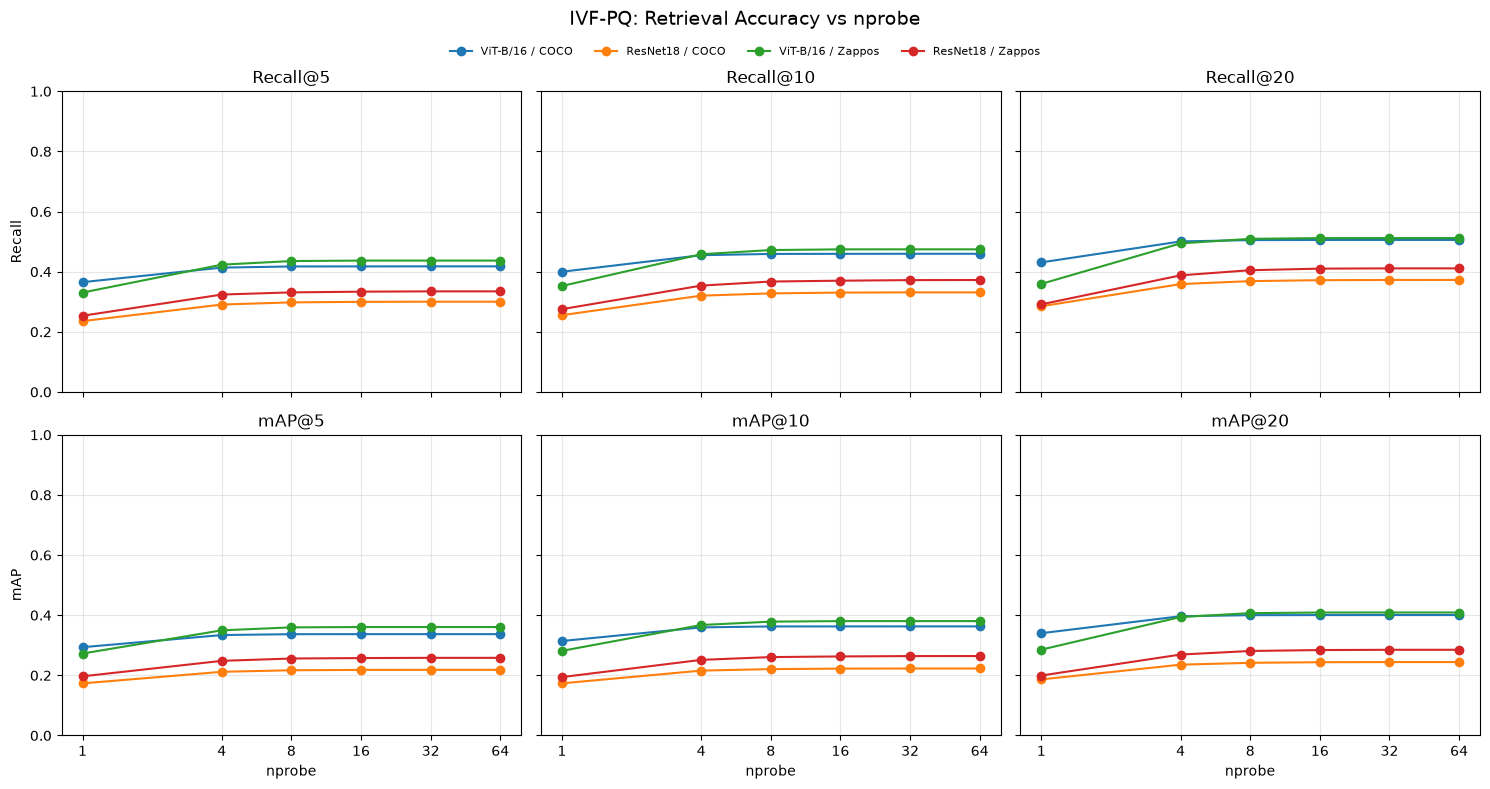

In [12]:
accuracy_figures("IVF-PQ", "ivfpq")

### IVF-PQ: speed

saved media\ivfpq_latency.png


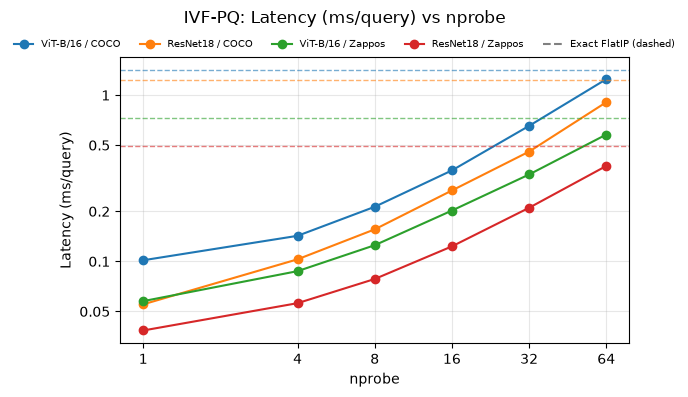

In [13]:
cost_figure("IVF-PQ", "ivfpq", "latency")

### IVF-PQ: memory

saved media\ivfpq_index_size.png


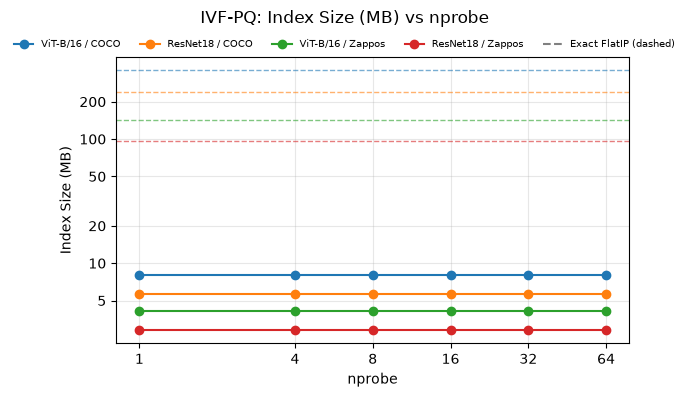

In [14]:
cost_figure("IVF-PQ", "ivfpq", "index_size")

## HNSW (efSearch)

`efSearch`: size of the candidate list during the graph search (`M = 32`, `efConstruction = 200`).

### HNSW: accuracy

The y-axis is zoomed to 0.93-1.0.

saved media\hnsw_recall_at_5.png
saved media\hnsw_recall_at_10.png
saved media\hnsw_recall_at_20.png
saved media\hnsw_map_at_5.png
saved media\hnsw_map_at_10.png
saved media\hnsw_map_at_20.png
saved media\hnsw_accuracy_grid.png


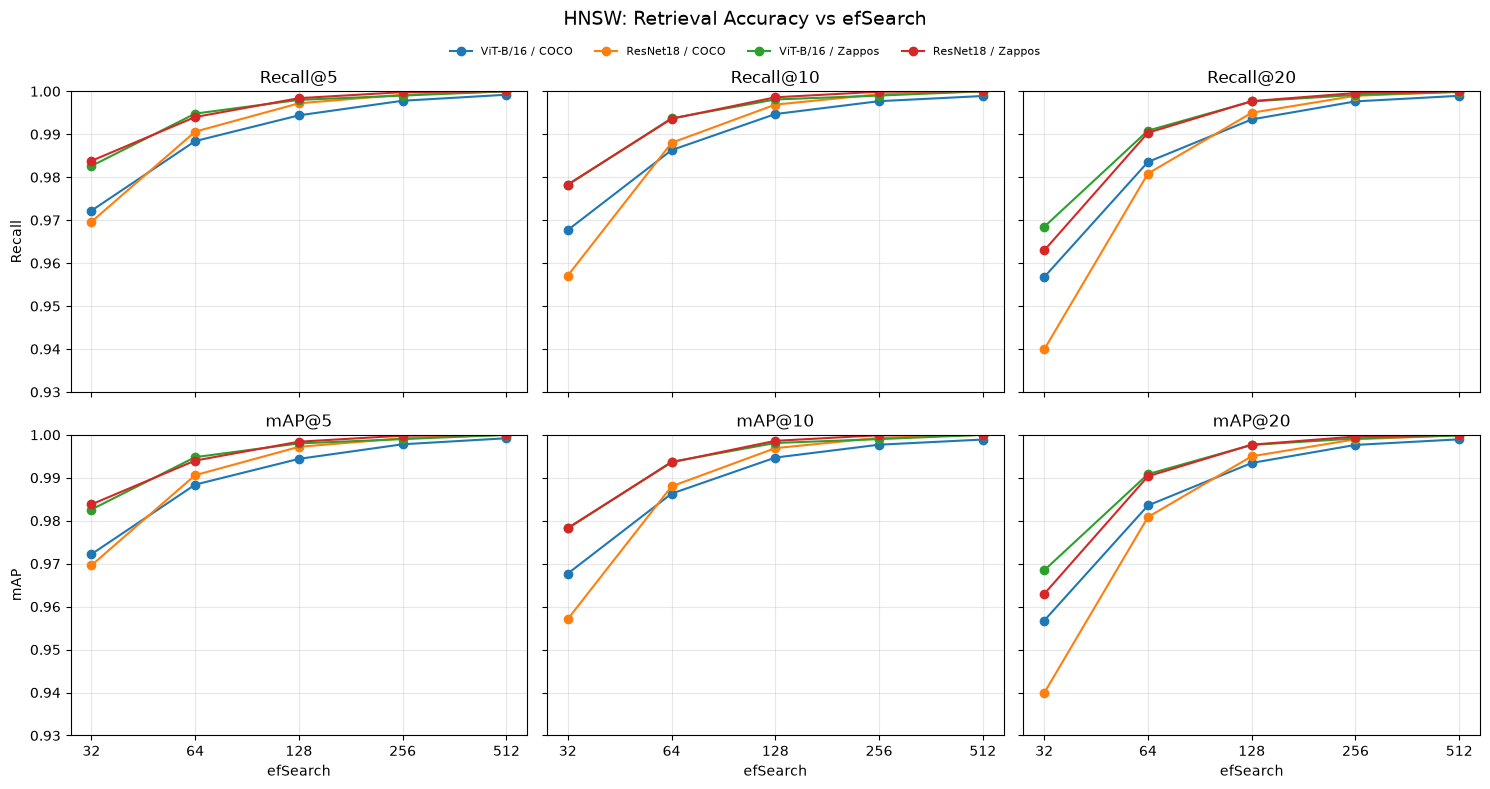

In [15]:
accuracy_figures("HNSW", "hnsw", ylim=(0.93, 1.0))

### HNSW: speed

saved media\hnsw_latency.png


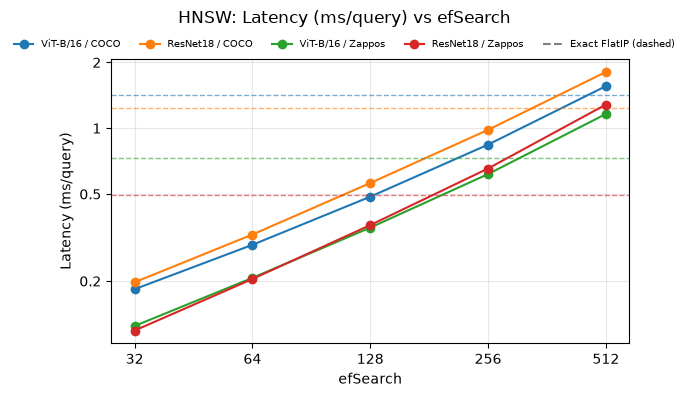

In [16]:
cost_figure("HNSW", "hnsw", "latency")

### HNSW: memory

saved media\hnsw_index_size.png


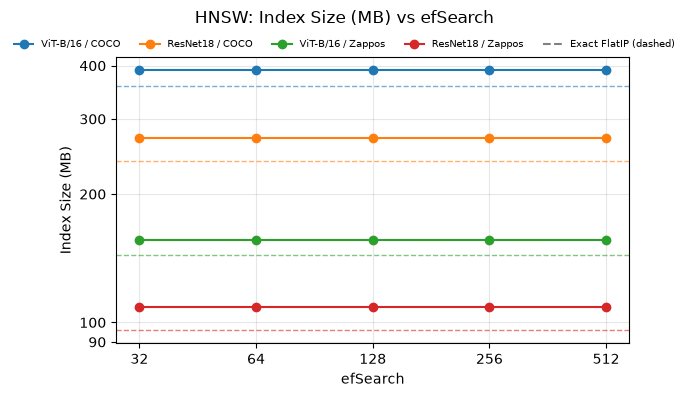

In [17]:
cost_figure("HNSW", "hnsw", "index_size")

## HNSW-PQ (efSearch)

HNSW with PQ-compressed vectors (`m` = 48 for ViT, 32 for ResNet18).

### HNSW-PQ: accuracy

saved media\hnswpq_recall_at_5.png
saved media\hnswpq_recall_at_10.png
saved media\hnswpq_recall_at_20.png
saved media\hnswpq_map_at_5.png
saved media\hnswpq_map_at_10.png
saved media\hnswpq_map_at_20.png
saved media\hnswpq_accuracy_grid.png


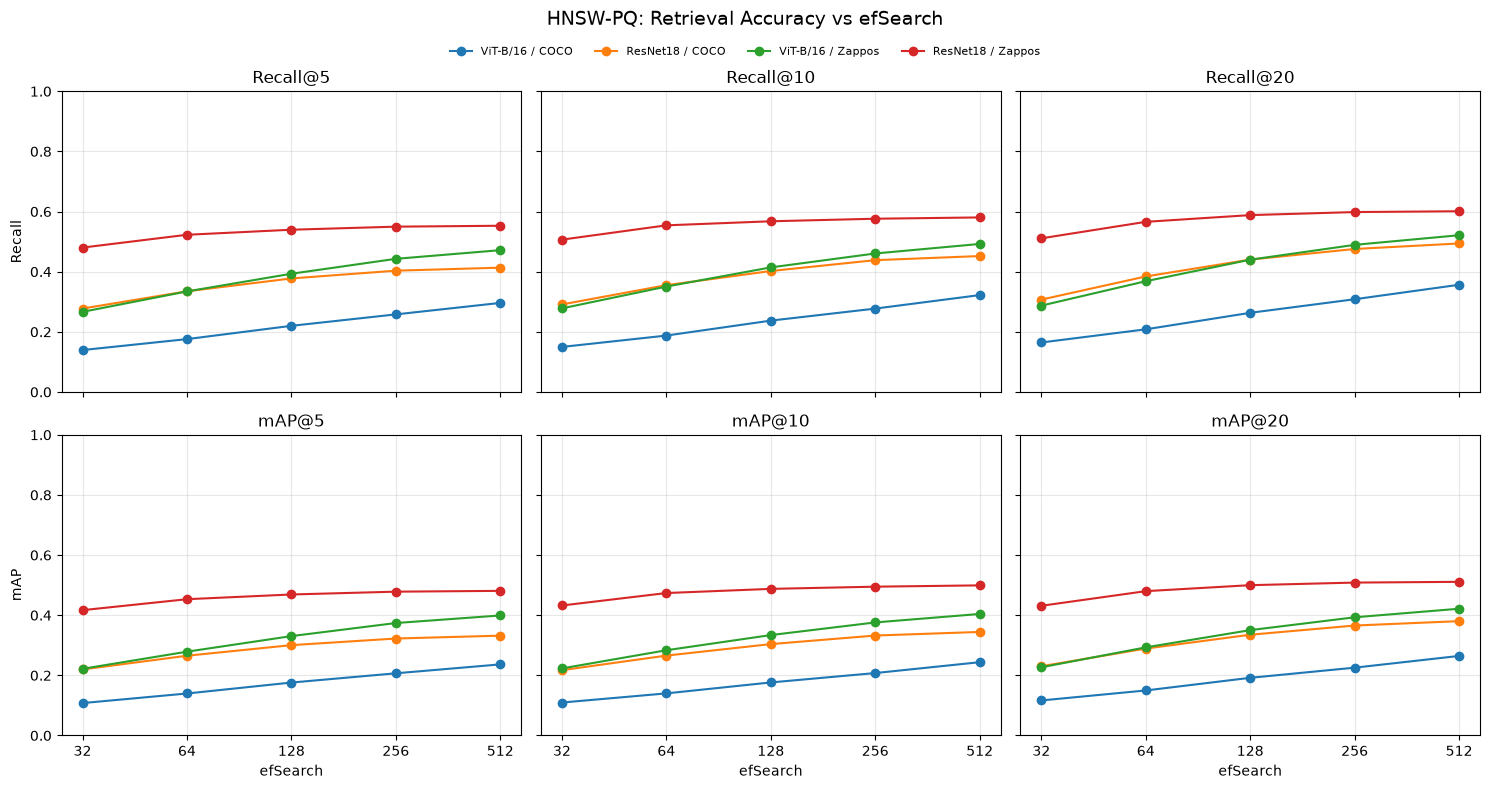

In [18]:
accuracy_figures("HNSW-PQ", "hnswpq")

### HNSW-PQ: speed

saved media\hnswpq_latency.png


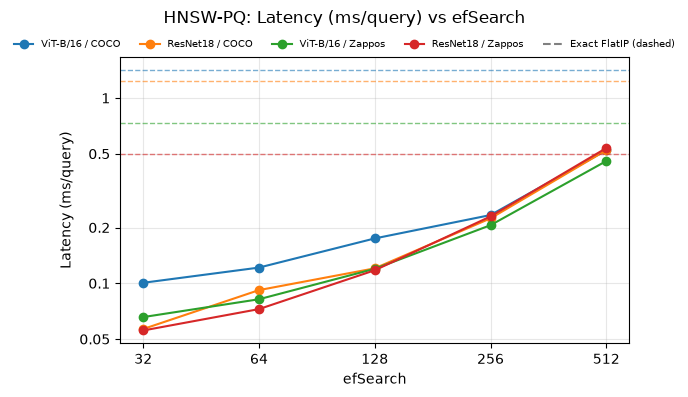

In [19]:
cost_figure("HNSW-PQ", "hnswpq", "latency")

### HNSW-PQ: memory

saved media\hnswpq_index_size.png


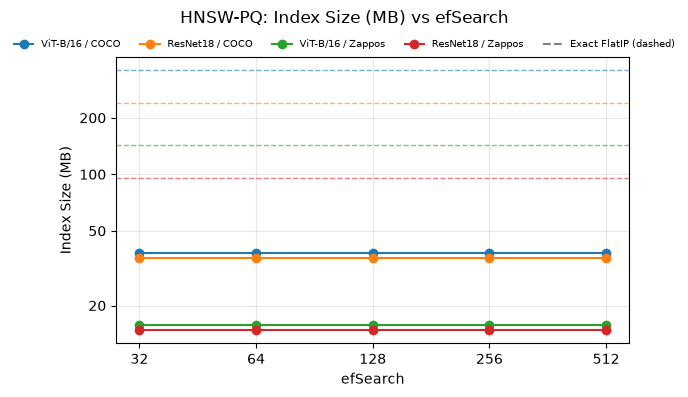

In [20]:
cost_figure("HNSW-PQ", "hnswpq", "index_size")

## Choosing the best setting

Two scores from `scoring.py`:

- **Weighted score**: 0.6 accuracy + 0.3 speed + 0.1 memory (speed and memory relative to exact search, log scale).
- **Knee score**: point of diminishing returns of Recall@10 vs log latency within each sweep.

In [21]:
from scoring import ACC_METRIC, WEIGHTS, best_overall, best_per_config, knee_score, weighted_score

SCORES = {"weighted": "Weighted score", "knee": "Knee score"}

# Every swept setting (Exact FlatIP has no parameter) with both scores.
scored = results[results["param_name"].notna()].copy()
scored["weighted"] = weighted_score(scored, WEIGHTS)
scored["knee"] = knee_score(scored)

# Best setting of each method in each experiment, one table per score.
for score, title in SCORES.items():
    picks = (best_per_config(scored, score)
             .pivot(index="algorithm", columns="config", values="param_value")
             .reindex(index=[m for m in METHOD_ORDER if m in SWEEP_PARAM], columns=meta.index)
             .rename(columns=meta["label"]).astype(int))
    picks.insert(0, "parameter", picks.index.map(SWEEP_PARAM))
    print(f"{title}: best setting per experiment")
    display(picks)

# One setting per method: highest mean score over the four experiments.
overall = []
for score, title in SCORES.items():
    best = best_overall(scored, score).set_index("algorithm")
    overall.append(best.drop(columns=score).rename(columns=lambda c: f"{score}: {c}"))
overall = (pd.concat(overall, axis=1)
           .reindex([m for m in METHOD_ORDER if m in SWEEP_PARAM]))
overall.insert(0, "parameter", overall.index.map(SWEEP_PARAM))
print(f"Best setting per method (mean over experiments; {ACC_METRIC} shown for reference)")
display(overall.round(3))

Weighted score: best setting per experiment


config,parameter,ViT-B/16 / COCO,ResNet18 / COCO,ViT-B/16 / Zappos,ResNet18 / Zappos
algorithm,,,,,
LSH,nbits,512,512,512,512
IVF-Flat,nprobe,4,8,8,8
IVF-PQ,nprobe,4,1,4,4
HNSW,efSearch,32,32,32,32
HNSW-PQ,efSearch,256,128,128,64


Knee score: best setting per experiment


config,parameter,ViT-B/16 / COCO,ResNet18 / COCO,ViT-B/16 / Zappos,ResNet18 / Zappos
algorithm,,,,,
LSH,nbits,512,512,512,512
IVF-Flat,nprobe,4,8,8,8
IVF-PQ,nprobe,4,4,4,4
HNSW,efSearch,128,64,64,64
HNSW-PQ,efSearch,256,128,128,64


Best setting per method (mean over experiments; recall_at_10 shown for reference)


,parameter,weighted: param_value,weighted: recall_at_10,weighted: speedup,weighted: compression,knee: param_value,knee: recall_at_10,knee: speedup,knee: compression
algorithm,,,,,,,,,
LSH,nbits,512.0,0.412,4.176,31.038,512.0,0.412,4.176,31.038
IVF-Flat,nprobe,8.0,0.935,4.069,0.993,8.0,0.935,4.069,0.993
IVF-PQ,nprobe,4.0,0.397,9.777,38.739,4.0,0.397,9.777,38.739
HNSW,efSearch,32.0,0.970,5.992,0.901,64.0,0.990,3.639,0.901
HNSW-PQ,efSearch,128.0,0.405,7.164,7.920,128.0,0.405,7.164,7.920


## Effect of PQ compression

`pq_sweep.py` varies the PQ code size `m` (bytes per vector) for IVF-PQ and HNSW-PQ,
with `nprobe` / `efSearch` fixed at each config's knee pick:

| Config | IVF `nprobe` | HNSW `efSearch` |
|---|---|---|
| ViT-B/16 / COCO | 4 | 128 |
| ResNet18 / COCO | 8 | 64 |
| ViT-B/16 / Zappos | 8 | 64 |
| ResNet18 / Zappos | 8 | 64 |

Dashed line = the full-vector partner (IVF-Flat or HNSW) at the same setting.

In [22]:
# PQ sweep results from pq_sweep.py. Each configuration fixes nprobe / efSearch
# at its own knee pick of IVF-Flat / HNSW and varies m.
PQ_PAIRS = {"IVF-PQ": "IVF-Flat", "HNSW-PQ": "HNSW"}   # PQ method -> full-vector partner
PQ_COLUMNS = {"recall_at_10": "Recall@10", "map_at_10": "mAP@10",
              "latency_ms_per_query": "Latency (ms)", "compression": "Compression (x)"}

pq_rows = []
for key in meta.index:
    path = results_dir(key) / "pq_sweep" / "pq_sweep_results.json"
    if not path.exists():
        print(f"{key}: no pq_sweep_results.json - run pq_sweep.py --config {key}")
        continue
    for r in json.loads(path.read_text())["results"]:
        pq_rows.append({
            "config": key,
            "algorithm": r["algorithm"],
            # m is the swept parameter here; the fixed search setting is kept aside.
            "param_name": "m",
            "param_value": r["parameters"]["m"],
            "search_value": r["parameters"][SWEEP_PARAM[r["algorithm"]]],
            **{k: v for k, v in r.items() if k not in ("algorithm", "parameters")},
        })

# pq: one row per (config, PQ method, m). pq_reference[method]: its
# full-vector partner at the same search setting, indexed by config ("no PQ").
pq, pq_reference = None, {}
if pq_rows:
    pq = pd.DataFrame(pq_rows)
    pq["compression"] = pq["config"].map(exact["index_size_mb"]) / pq["index_size_mb"]
    for pq_algo, flat_algo in PQ_PAIRS.items():
        sweep = pick(pq_algo, data=pq).sort_values("param_value")
        fixed = (sweep[["config", "search_value"]].drop_duplicates()
                 .rename(columns={"search_value": "param_value"}))
        pq_reference[pq_algo] = (pick(flat_algo).merge(fixed, on=["config", "param_value"])
                                 .set_index("config"))
        rows = pd.concat([pq_reference[pq_algo].reset_index().assign(pq="no PQ"),
                          sweep.assign(pq="m = " + sweep["param_value"].astype(str))])
        table = (rows.pivot(index="pq", columns="config", values=list(PQ_COLUMNS))
                 .reindex(rows["pq"].unique())
                 .reindex(columns=[c for c in meta.index if c in fixed["config"].values], level=1)
                 .rename(columns=PQ_COLUMNS, level=0)
                 .rename(columns=meta["label"], level=1))
        table.index.name = None
        setting = ", ".join(f"{meta.loc[c, 'label']}: {v:g}" for c, v in fixed.itertuples(index=False))
        print(f"{pq_algo} vs {flat_algo} at {SWEEP_PARAM[flat_algo]} = ({setting})")
        display(table.round(3))

IVF-PQ vs IVF-Flat at nprobe = (ViT-B/16 / COCO: 4, ResNet18 / COCO: 8, ResNet18 / Zappos: 8, ViT-B/16 / Zappos: 8)


Recall@10                                                      \
config  ViT-B/16 / COCO ResNet18 / COCO ViT-B/16 / Zappos ResNet18 / Zappos   
no PQ             0.913           0.924             0.946             0.907   
m = 8             0.084           0.149             0.179             0.185   
m = 16            0.156           0.223             0.263             0.264   
m = 32            0.345           0.328             0.392             0.367   
m = 64            0.531           0.502             0.536             0.530   
m = 128           0.692           0.689             0.707             0.712   

                 mAP@10                                                      \
config  ViT-B/16 / COCO ResNet18 / COCO ViT-B/16 / Zappos ResNet18 / Zappos   
no PQ             0.913           0.924             0.946             0.907   
m = 8             0.039           0.076             0.096             0.101   
m = 16            0.083           0.129             0.165             0.162   
m = 32            0.246           0.221             0.287             0.261   
m = 64            0.443           0.399             0.450             0.445   
m = 128           0.645           0.635             0.660             0.668   

           Latency (ms)                                                      \
config  ViT-B/16 / COCO ResNet18 / COCO ViT-B/16 / Zappos ResNet18 / Zappos   
no PQ             0.231           0.290             0.187             0.103   
m = 8             0.035           0.054             0.047             0.033   
m = 16            0.048           0.074             0.057             0.046   
m = 32            0.072           0.142             0.089             0.080   
m = 64            0.141           0.275             0.176             0.148   
m = 128           0.360           0.540             0.350             0.298   

        Compression (x)                                                      
config  ViT-B/16 / COCO ResNet18 / COCO ViT-B/16 / Zappos ResNet18 / Zappos  
no PQ             0.995           0.994             0.992             0.991  
m = 8           106.415          83.304            63.829            54.710  
m = 16           83.324          62.851            54.732            45.076  
m = 32           58.107          42.153            42.591            33.337  
m = 64           36.197          25.414            29.502            21.919  
m = 128          20.636          14.165            18.272            13.009

HNSW-PQ vs HNSW at efSearch = (ViT-B/16 / COCO: 128, ResNet18 / COCO: 64, ResNet18 / Zappos: 64, ViT-B/16 / Zappos: 64)


Recall@10                                                      \
config  ViT-B/16 / COCO ResNet18 / COCO ViT-B/16 / Zappos ResNet18 / Zappos   
no PQ             0.995           0.988             0.994             0.994   
m = 8             0.061           0.077             0.098             0.132   
m = 16            0.106           0.129             0.159             0.245   
m = 32            0.190           0.355             0.233             0.554   
m = 64            0.366           0.624             0.499             0.725   
m = 128           0.731           0.782             0.759             0.850   

                 mAP@10                                                      \
config  ViT-B/16 / COCO ResNet18 / COCO ViT-B/16 / Zappos ResNet18 / Zappos   
no PQ             0.995           0.988             0.994             0.994   
m = 8             0.029           0.041             0.049             0.080   
m = 16            0.058           0.081             0.099             0.173   
m = 32            0.128           0.266             0.171             0.474   
m = 64            0.299           0.547             0.428             0.677   
m = 128           0.687           0.749             0.720             0.832   

           Latency (ms)                                                      \
config  ViT-B/16 / COCO ResNet18 / COCO ViT-B/16 / Zappos ResNet18 / Zappos   
no PQ             0.486           0.327             0.207             0.204   
m = 8             0.066           0.045             0.043             0.041   
m = 16            0.070           0.059             0.049             0.054   
m = 32            0.117           0.086             0.070             0.071   
m = 64            0.188           0.169             0.089             0.162   
m = 128           0.356           0.351             0.260             0.292   

        Compression (x)                                                      
config  ViT-B/16 / COCO ResNet18 / COCO ViT-B/16 / Zappos ResNet18 / Zappos  
no PQ             0.919           0.883             0.919             0.883  
m = 8            10.717           7.199            10.369             7.039  
m = 16           10.426           7.002            10.096             6.851  
m = 32            9.889           6.639             9.592             6.503  
m = 64            8.966           6.015             8.720             5.903  
m = 128           7.555           5.063             7.380             4.984

### IVF-PQ vs m: accuracy

saved media\pqsweep_ivfpq_recall_at_5.png
saved media\pqsweep_ivfpq_recall_at_10.png
saved media\pqsweep_ivfpq_recall_at_20.png
saved media\pqsweep_ivfpq_map_at_5.png
saved media\pqsweep_ivfpq_map_at_10.png
saved media\pqsweep_ivfpq_map_at_20.png
saved media\pqsweep_ivfpq_accuracy_grid.png


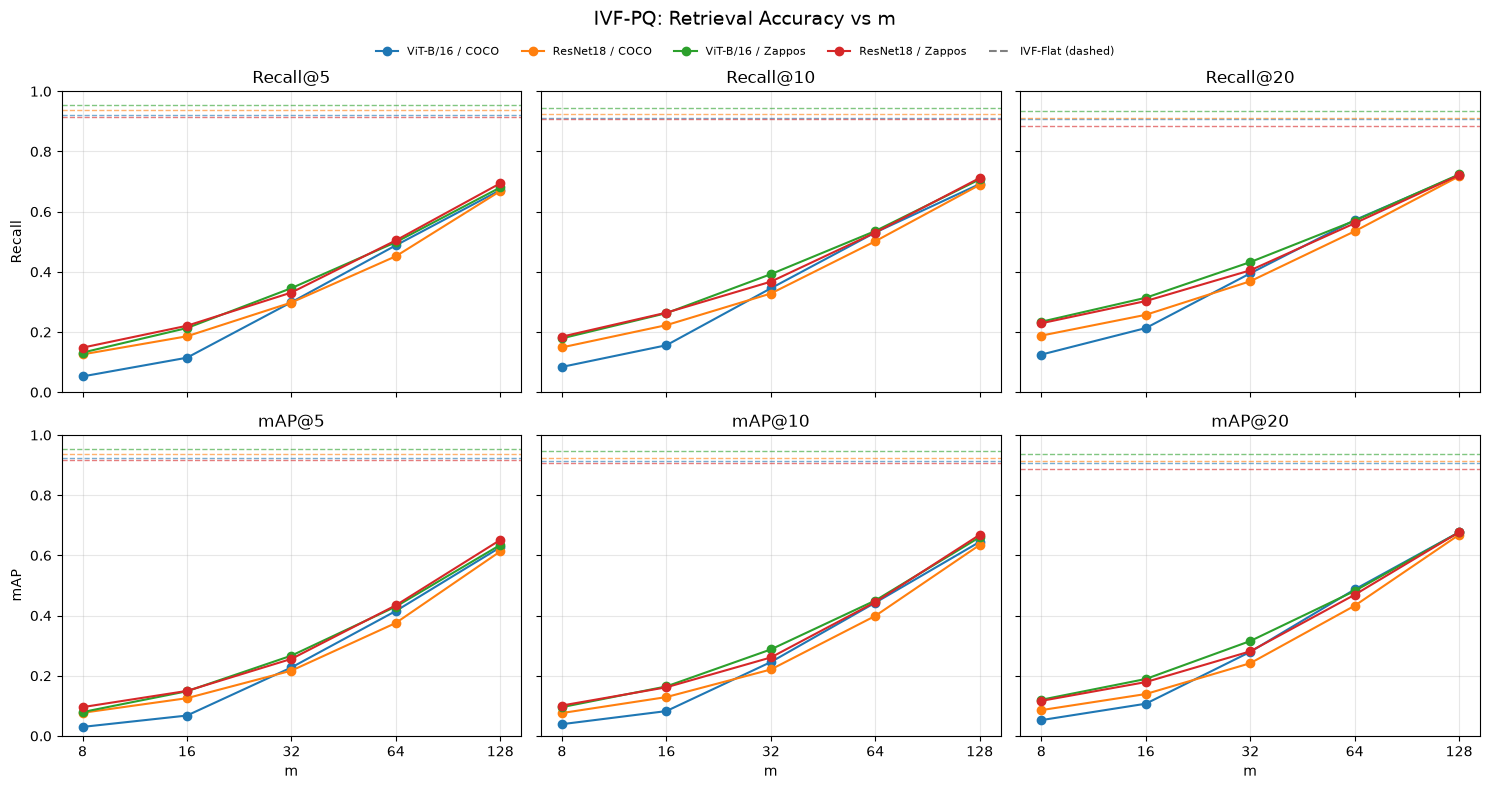

In [23]:
if pq is not None:
    accuracy_figures("IVF-PQ", "pqsweep_ivfpq", data=pq, reference=pq_reference["IVF-PQ"], reference_label="IVF-Flat")

### IVF-PQ vs m: speed

saved media\pqsweep_ivfpq_latency.png


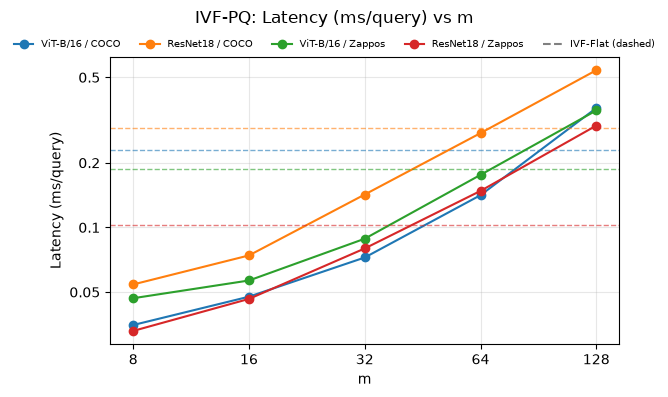

In [24]:
if pq is not None:
    cost_figure("IVF-PQ", "pqsweep_ivfpq", "latency", data=pq, reference=pq_reference["IVF-PQ"], reference_label="IVF-Flat")

### IVF-PQ vs m: memory

saved media\pqsweep_ivfpq_index_size.png


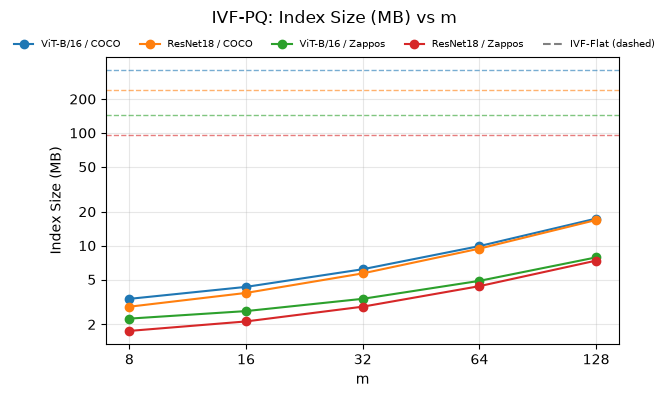

In [25]:
if pq is not None:
    cost_figure("IVF-PQ", "pqsweep_ivfpq", "index_size", data=pq, reference=pq_reference["IVF-PQ"], reference_label="IVF-Flat")

### IVF-PQ vs m: build time

saved media\pqsweep_ivfpq_build_time.png


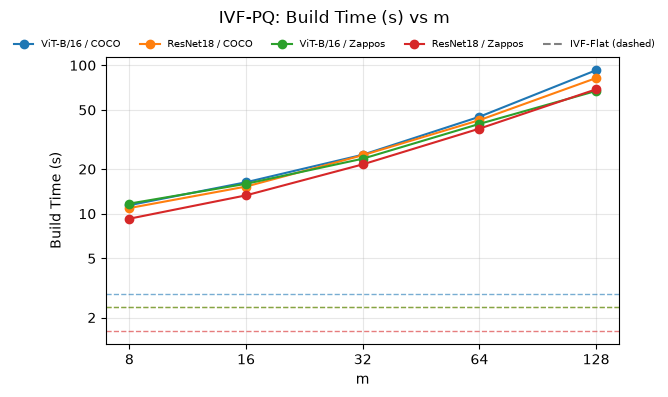

In [26]:
if pq is not None:
    cost_figure("IVF-PQ", "pqsweep_ivfpq", "build_time", data=pq,
                reference=pq_reference["IVF-PQ"], reference_label="IVF-Flat")

### HNSW-PQ vs m: accuracy

saved media\pqsweep_hnswpq_recall_at_5.png
saved media\pqsweep_hnswpq_recall_at_10.png
saved media\pqsweep_hnswpq_recall_at_20.png
saved media\pqsweep_hnswpq_map_at_5.png
saved media\pqsweep_hnswpq_map_at_10.png
saved media\pqsweep_hnswpq_map_at_20.png
saved media\pqsweep_hnswpq_accuracy_grid.png


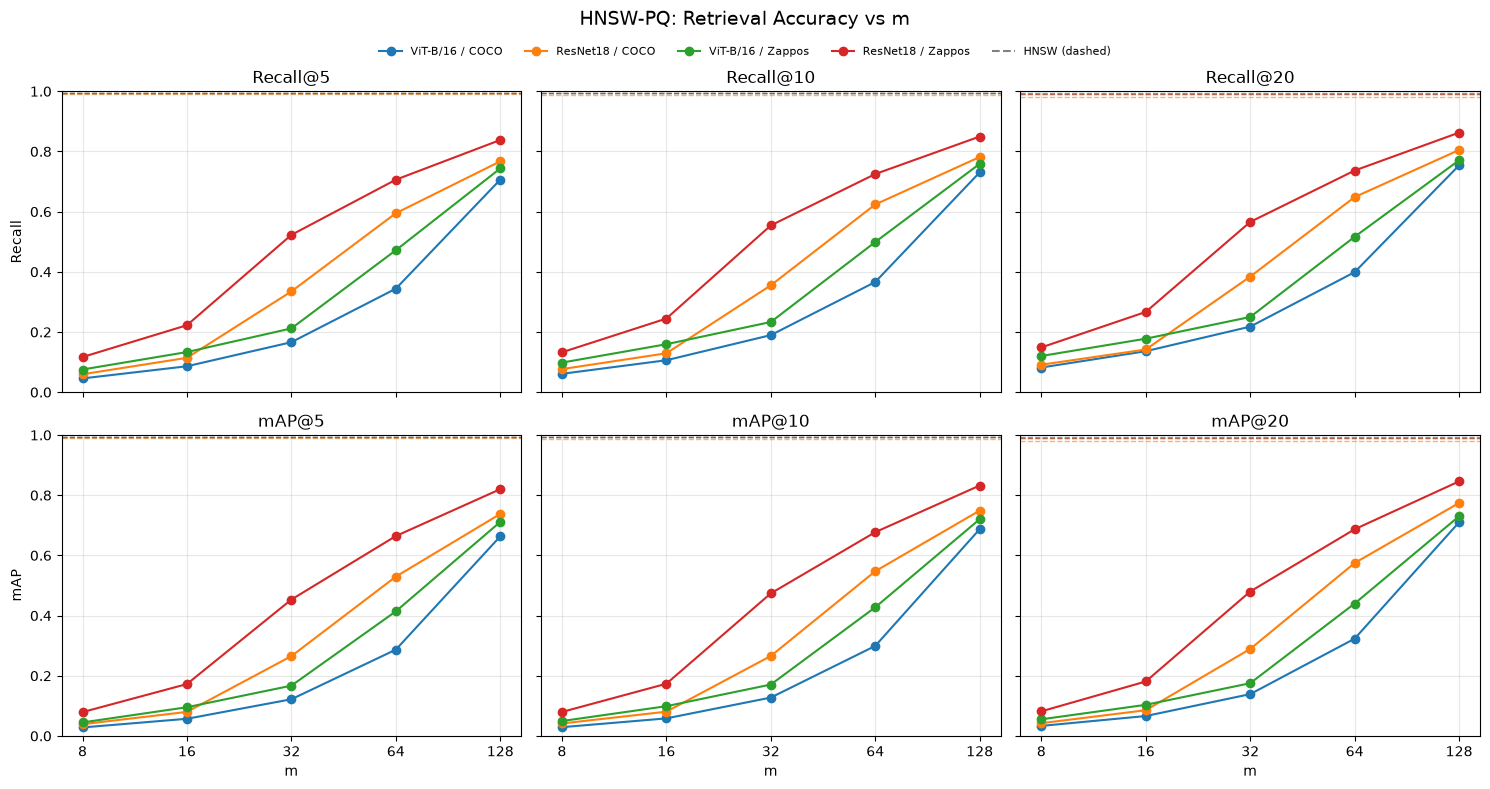

In [27]:
if pq is not None:
    accuracy_figures("HNSW-PQ", "pqsweep_hnswpq", data=pq, reference=pq_reference["HNSW-PQ"], reference_label="HNSW")

### HNSW-PQ vs m: speed

saved media\pqsweep_hnswpq_latency.png


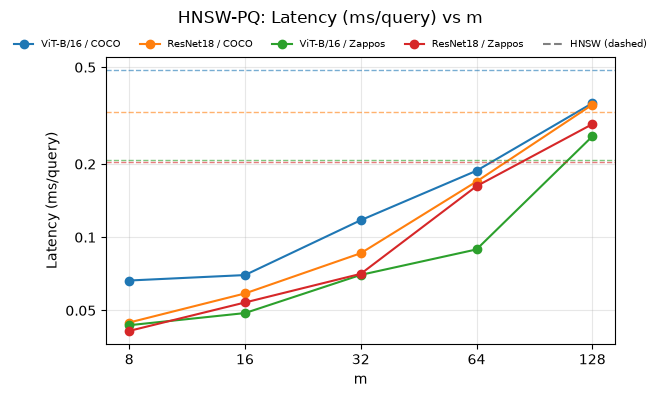

In [28]:
if pq is not None:
    cost_figure("HNSW-PQ", "pqsweep_hnswpq", "latency", data=pq, reference=pq_reference["HNSW-PQ"], reference_label="HNSW")

### HNSW-PQ vs m: memory

saved media\pqsweep_hnswpq_index_size.png


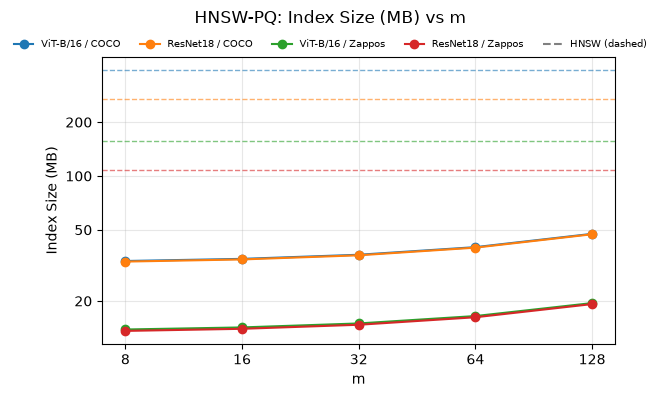

In [29]:
if pq is not None:
    cost_figure("HNSW-PQ", "pqsweep_hnswpq", "index_size", data=pq, reference=pq_reference["HNSW-PQ"], reference_label="HNSW")

### HNSW-PQ vs m: build time

saved media\pqsweep_hnswpq_build_time.png


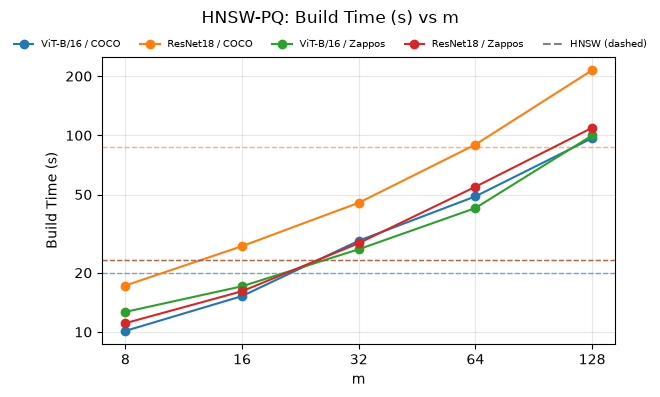

In [30]:
if pq is not None:
    cost_figure("HNSW-PQ", "pqsweep_hnswpq", "build_time", data=pq,
                reference=pq_reference["HNSW-PQ"], reference_label="HNSW")

## Ranking quality: mAP vs Recall

mAP@K / Recall@K: 1.0 means every true neighbour found is ranked above every wrong result.
IVF-Flat and HNSW are always 1.0 (black dashed line).

In [31]:
# mAP@K / Recall@K for every row (1.0 = found neighbours ranked perfectly).
RATIO_METRICS = [(f"map_recall_ratio_at_{k}", f"mAP@{k} / Recall@{k}") for k in (5, 10, 20)]


def add_ratio_columns(df):
    for k in (5, 10, 20):
        df[f"map_recall_ratio_at_{k}"] = df[f"map_at_{k}"] / df[f"recall_at_{k}"]


def ratio_figure(algorithm, file_prefix, data=None, reference_label="Exact FlatIP"):
    # One panel per K (@5 / @10 / @20) -> media/<file_prefix>_map_recall_ratio.png.
    # The dashed black line at 1.0 is the full-vector method(s) in `reference_label`,
    # whose mAP always equals their Recall.
    param = pick(algorithm, data=data)["param_name"].iloc[0]
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
    for ax, (metric, label) in zip(axes, RATIO_METRICS):
        plot_sweep(ax, algorithm, metric, label, ylim=(0, 1.05), data=data)
        ax.axhline(1.0, ls="--", lw=1.5, color="black",
                   label=f"{reference_label} (full vectors, always 1.0)")
        ax.set_title(label)
        ax.label_outer()
    axes[0].set_ylabel("mAP / Recall")
    fig.suptitle(f"{algorithm}: mAP / Recall vs {param}", fontsize=14)
    legend_above(fig, axes[0])
    save_figure(fig, f"{file_prefix}_map_recall_ratio")
    plt.show()


add_ratio_columns(results)
if pq is not None:
    add_ratio_columns(pq)

### LSH vs nbits

saved media\lsh_map_recall_ratio.png


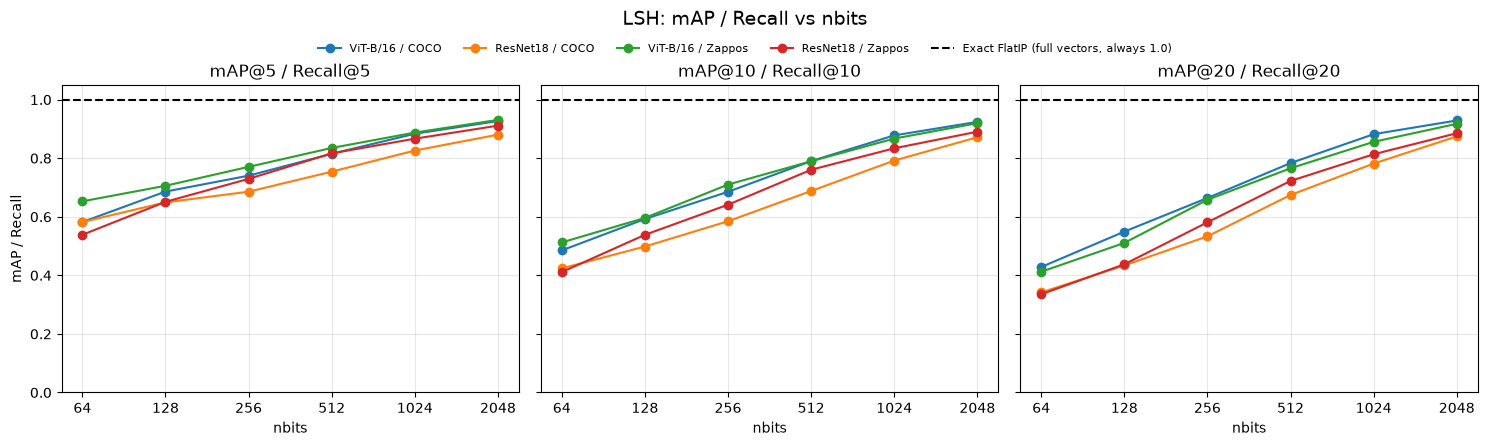

In [32]:
ratio_figure("LSH", "lsh")

### IVF-PQ vs m

saved media\pqsweep_ivfpq_map_recall_ratio.png


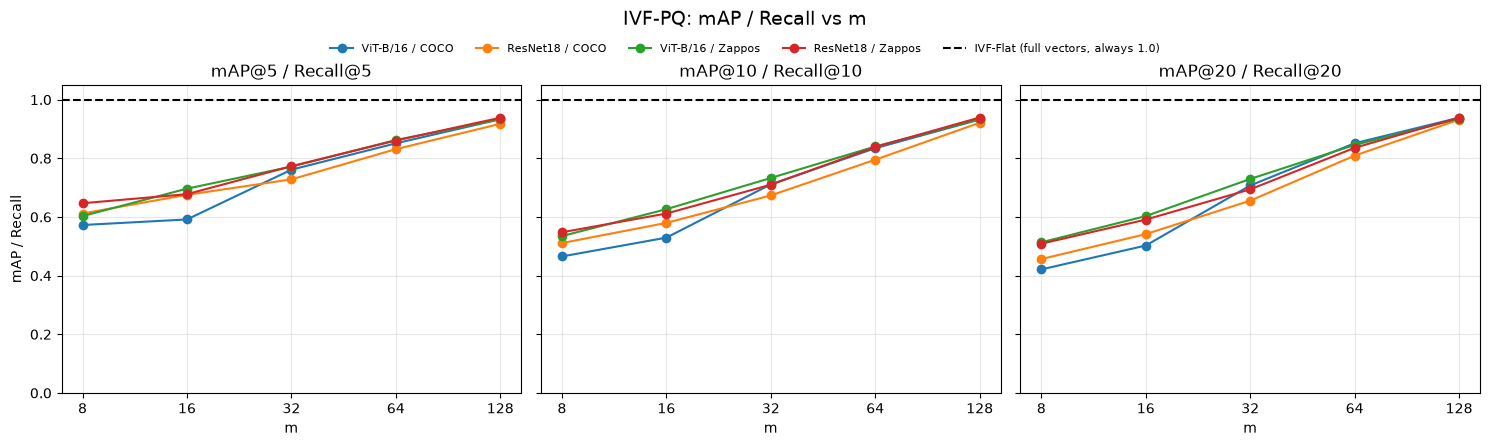

In [33]:
if pq is not None:
    ratio_figure("IVF-PQ", "pqsweep_ivfpq", data=pq, reference_label="IVF-Flat")

### HNSW-PQ vs m

saved media\pqsweep_hnswpq_map_recall_ratio.png


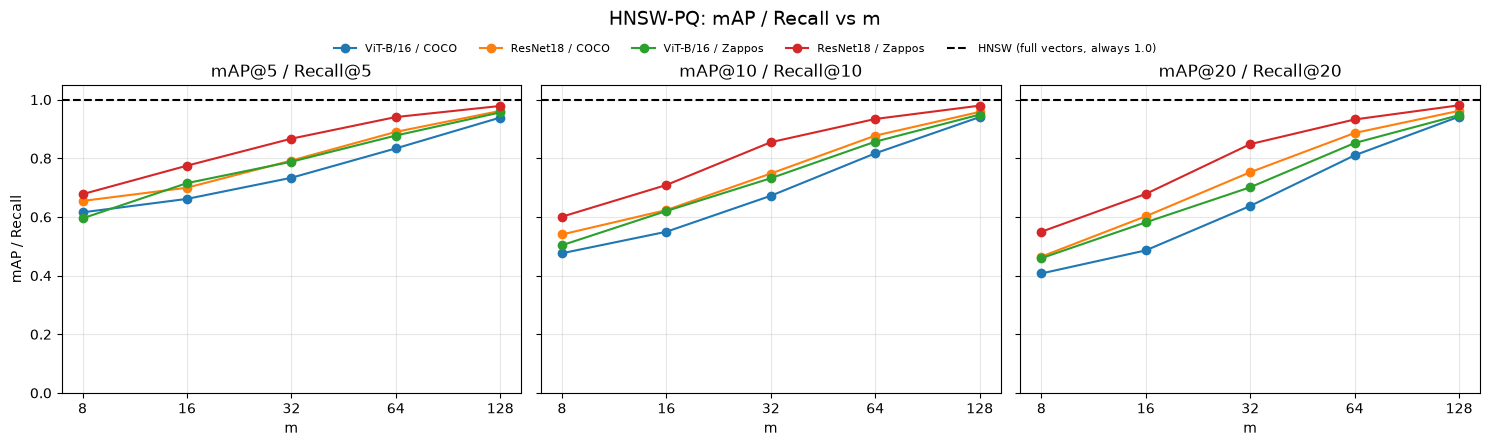

In [34]:
if pq is not None:
    ratio_figure("HNSW-PQ", "pqsweep_hnswpq", data=pq, reference_label="HNSW")

## Which model and method to use

Top 5 per dataset by weighted score: first each model x method at its best setting,
then every model x method x setting. Exact FlatIP is left out.

In [35]:
from scoring import rank_methods, rank_settings

# One table per dataset and ranking; the methods ranking hides the setting.
RANKINGS = {"methods": (rank_methods, False), "methods and settings": (rank_settings, True)}
for name, (rank, show_setting) in RANKINGS.items():
    for dataset, top in rank(scored, "weighted").groupby("dataset", sort=False):
        table = pd.DataFrame({
            "model": top["model_label"],
            "method": top["algorithm"],
            "parameter": top["setting"],
            "weighted score": top["weighted"],
            "Recall@10": top["recall_at_10"],
            "latency (ms/query)": top["latency_ms_per_query"],
            "speedup": top["speedup"],
            "compression": top["compression"],
        }).round(3)
        if not show_setting:
            table = table.drop(columns="parameter")
        table.index = pd.RangeIndex(1, len(table) + 1, name="rank")
        print(f"{DATASETS[dataset]['label']}: top {len(table)} {name} by weighted score")
        display(table)

COCO: top 5 methods by weighted score


,model,method,weighted score,Recall@10,latency (ms/query),speedup,compression
rank,,,,,,,
1,ViT-B/16,HNSW,0.710,0.968,0.184,7.691,0.919
2,ResNet18,HNSW,0.690,0.957,0.198,6.253,0.883
3,ViT-B/16,IVF-Flat,0.667,0.913,0.231,6.124,0.995
4,ResNet18,IVF-Flat,0.649,0.924,0.290,4.257,0.994
5,ViT-B/16,IVF-PQ,0.478,0.455,0.143,9.911,44.607


Zappos: top 5 methods by weighted score


,model,method,weighted score,Recall@10,latency (ms/query),speedup,compression
rank,,,,,,,
1,ViT-B/16,HNSW,0.699,0.978,0.125,5.844,0.919
2,ResNet18,HNSW,0.676,0.978,0.119,4.182,0.883
3,ViT-B/16,IVF-Flat,0.655,0.946,0.187,3.889,0.992
4,ResNet18,IVF-Flat,0.644,0.907,0.103,4.816,0.991
5,ResNet18,HNSW-PQ,0.471,0.554,0.073,6.846,6.503


COCO: top 5 methods and settings by weighted score


,model,method,parameter,weighted score,Recall@10,latency (ms/query),speedup,compression
rank,,,,,,,,
1,ViT-B/16,HNSW,efSearch=32,0.710,0.968,0.184,7.691,0.919
2,ViT-B/16,HNSW,efSearch=64,0.692,0.986,0.293,4.821,0.919
3,ResNet18,HNSW,efSearch=32,0.690,0.957,0.198,6.253,0.883
4,ResNet18,HNSW,efSearch=64,0.676,0.988,0.327,3.783,0.883
5,ViT-B/16,IVF-Flat,nprobe=4,0.667,0.913,0.231,6.124,0.995


Zappos: top 5 methods and settings by weighted score


,model,method,parameter,weighted score,Recall@10,latency (ms/query),speedup,compression
rank,,,,,,,,
1,ViT-B/16,HNSW,efSearch=32,0.699,0.978,0.125,5.844,0.919
2,ViT-B/16,HNSW,efSearch=64,0.676,0.994,0.207,3.521,0.919
3,ResNet18,HNSW,efSearch=32,0.676,0.978,0.119,4.182,0.883
4,ViT-B/16,IVF-Flat,nprobe=8,0.655,0.946,0.187,3.889,0.992
5,ResNet18,HNSW,efSearch=64,0.651,0.994,0.204,2.430,0.883


## Corruption robustness

200 queries are corrupted (rotation, crop, brightness, blur, saturation, hue); the gallery stays clean.

| Metric | Comparison |
|---|---|
| **Embedding drift** | cosine(clean, corrupted) |
| **Exact-search Recall@10** | corrupted Exact vs clean Exact |
| **Fidelity** | corrupted ANN vs corrupted Exact |
| **End-to-End** | corrupted ANN vs clean Exact |
| **Stability** | corrupted ANN vs clean ANN |

- **Embedding drift** moves long before the
  ranking does, so it is shown first - a drifted embedding can still
  retrieve the same neighbours.

### Settings and original-level self-checks

In [36]:
# The corruption sweep and its ANN index view: settings, shared loaders and
# original-level self-checks. Needs results/<config>/robustness/ from
# pipeline/corruption.py (loaded in the setup cell as `corruption`) and
# results/<config>/index_robustness/ from pipeline/index_robustness.py.
sys.path.insert(0, str(EXPERIMENT_DIR / "pipeline"))
from perturbations import TRANSFORMS

K_SHOW = 10   # K displayed in every corruption figure
# Full-vector indexes only: the Step 3c results also cover the PQ variants -
# add "IVF-PQ" / "HNSW-PQ" back to this list to show them.
IR_ALGORITHMS = ["IVF-Flat", "HNSW"]

IR_KEYS = [k for k in meta.index
           if (results_dir(k) / "index_robustness" / "index_robustness_summary.csv").exists()]

def level_key(transform, level):
    """(transform index, level index) in the sweep's own order."""
    if transform == "original":
        return (-1, 0)
    for t, spec in enumerate(TRANSFORMS):
        if spec["name"] == transform:
            for l, value in enumerate(spec["values"]):
                if float(level) == float(value):
                    return (t, l)
    return (len(TRANSFORMS), 0)

if not IR_KEYS:
    ir_summary = None
    print("Index view skipped: no index-robustness results. Run, from the repository root:")
    print("  python experiments/ann-comparison/pipeline/corruption.py --config all")
    print("  python experiments/ann-comparison/pipeline/index_robustness.py --config all")
else:
    ir_summary = pd.concat(
        [pd.read_csv(results_dir(k) / "index_robustness" / "index_robustness_summary.csv",
                     keep_default_na=False)
         for k in IR_KEYS], ignore_index=True)
    ir_summary["order"] = [level_key(t, l)
                           for t, l in zip(ir_summary["transform"], ir_summary["level"])]

    # Settings per configuration. The original-level self-checks are internal:
    # stability must be exactly 1.0 and fidelity must equal end-to-end.
    overview = []
    for k in IR_KEYS:
        rows = ir_summary[ir_summary["config"] == k]
        for algorithm in IR_ALGORITHMS:
            original = rows[(rows["algorithm"] == algorithm)
                            & (rows["transform"] == "original")].iloc[0]
            assert float(original[f"stability_recall_at_{K_SHOW}_mean"]) == 1.0, (k, algorithm)
            overview.append({
                "config": meta.loc[k, "label"],
                "algorithm": algorithm,
                "setting": original["setting"],
                "index MB": round(float(original["index_size_mb"]), 1),
                "ms/variant": original["latency_ms_per_variant"],
            })
    display(pd.DataFrame(overview))
    for k in IR_KEYS:
        original = ir_summary[(ir_summary["config"] == k) & (ir_summary["transform"] == "original")]
        gap = (original[f"fidelity_recall_at_{K_SHOW}_mean"]
               - original[f"end_to_end_recall_at_{K_SHOW}_mean"]).abs().max()
        print(f"{meta.loc[k, 'label']:<20} original self-check: stability == 1.0 ok | "
              f"|fidelity - end_to_end| <= {gap:.4f}")

,config,algorithm,setting,index MB,ms/variant
0,ViT-B/16 / COCO,IVF-Flat,nprobe=4,360.3,0.2277
1,ViT-B/16 / COCO,HNSW,efSearch=64,390.4,0.1334
2,ResNet18 / COCO,IVF-Flat,nprobe=8,240.5,0.2656
3,ResNet18 / COCO,HNSW,efSearch=64,270.8,0.1821
4,ViT-B/16 / Zappos,IVF-Flat,nprobe=8,144.8,0.1942
5,ViT-B/16 / Zappos,HNSW,efSearch=32,156.4,0.0810
6,ResNet18 / Zappos,IVF-Flat,nprobe=8,96.6,0.1166
7,ResNet18 / Zappos,HNSW,efSearch=32,108.5,0.0670


ViT-B/16 / COCO      original self-check: stability == 1.0 ok | |fidelity - end_to_end| <= 0.0000
ResNet18 / COCO      original self-check: stability == 1.0 ok | |fidelity - end_to_end| <= 0.0000
ViT-B/16 / Zappos    original self-check: stability == 1.0 ok | |fidelity - end_to_end| <= 0.0000
ResNet18 / Zappos    original self-check: stability == 1.0 ok | |fidelity - end_to_end| <= 0.0000


### Embedding drift: cosine similarity

`cosine(clean, corrupted)` compares the corrupted query embedding
against the original. It moves long before the ranking does,
so it is shown first - a drifted embedding can still retrieve the same
neighbours.

saved media\corruption_exact_cosine.png


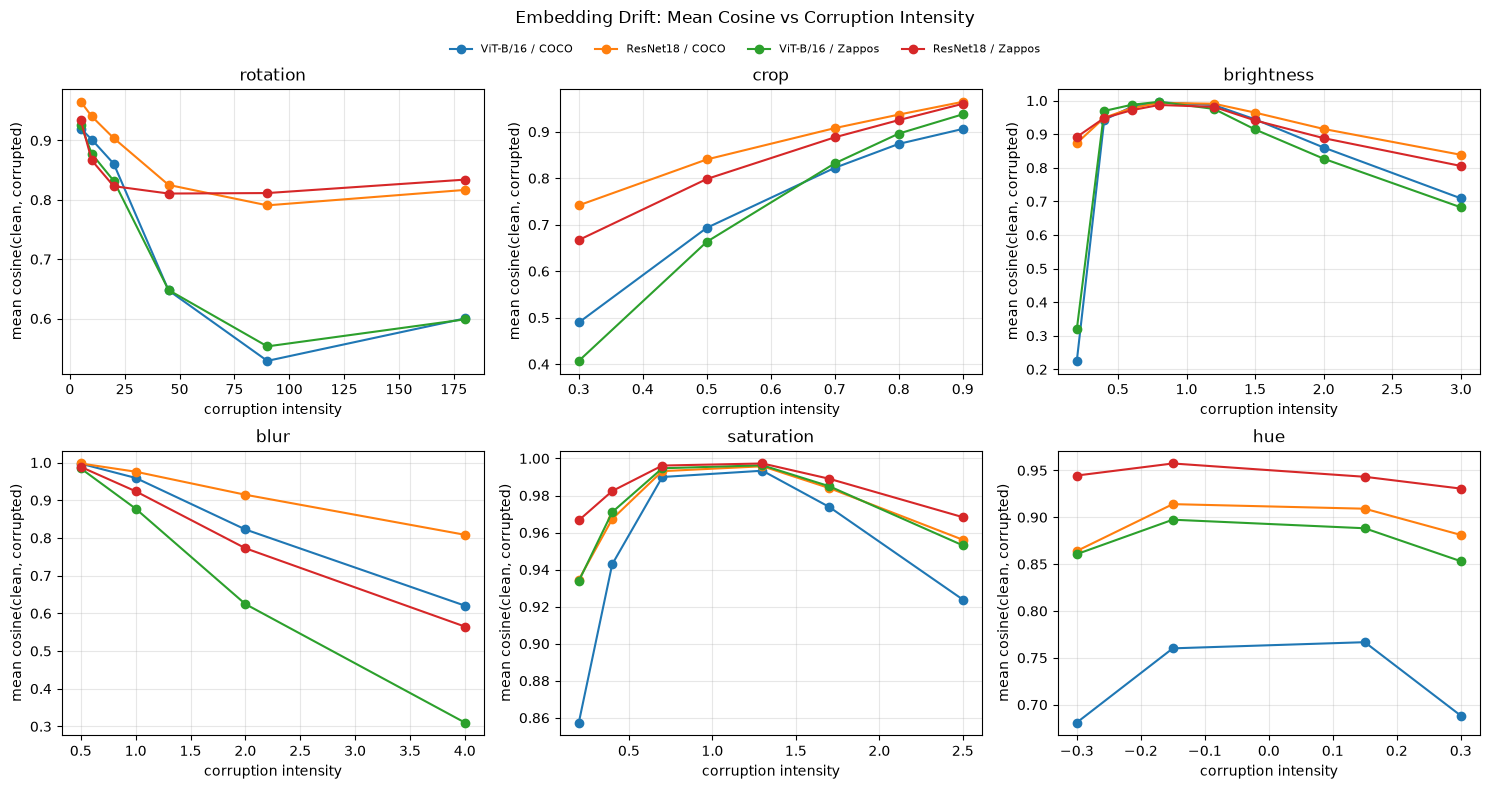

In [37]:
# The `corruption` frame was loaded in the setup cell. One panel per transform,
# one line per configuration, corrupted levels only.
if corruption is None:
    print("Embedding drift skipped: no corruption results. Run pipeline/corruption.py first.")
else:
    configs = [k for k in meta.index if (corruption["config"] == k).any()]

    fig, axes = plt.subplots(2, 3, figsize=(15, 8))
    for ax, spec in zip(axes.ravel(), TRANSFORMS):
        for k in configs:
            rows = (corruption[(corruption["config"] == k)
                               & (corruption["transform"] == spec["name"])]
                    .assign(level=lambda d: d["level"].astype(float))
                    .sort_values("level"))
            ax.plot(rows["level"], rows["cosine_mean"], marker="o",
                    color=CONFIG_COLORS[k], label=meta.loc[k, "label"])
        ax.set_title(spec["name"])
        ax.set_xlabel("corruption intensity")
        ax.set_ylabel("mean cosine(clean, corrupted)")
        ax.grid(alpha=0.3)
    fig.suptitle("Embedding Drift: Mean Cosine vs Corruption Intensity")
    legend_above(fig, axes[0][0])
    save_figure(fig, "corruption_exact_cosine")
    plt.show()

### Corruption robustness: Recall@10

saved media\corruption_exact_recall_at_10.png


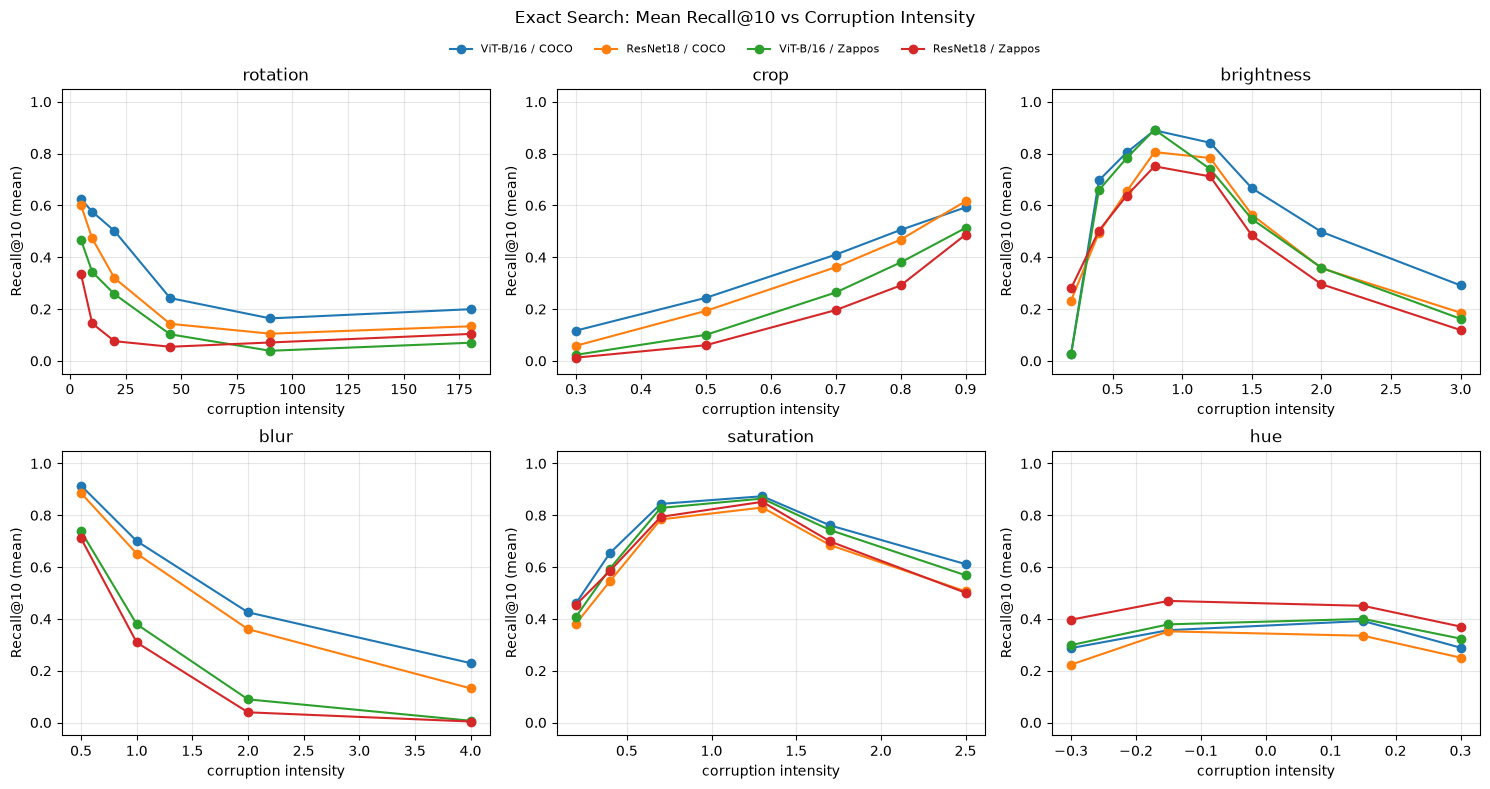

In [38]:
# Same format as the embedding-drift figure, now for exact-search Recall@10
# (the `corruption` frame was loaded in the setup cell).
if corruption is None:
    print("Exact-search Recall@10 skipped: no corruption results. Run pipeline/corruption.py first.")
else:
    configs = [k for k in meta.index if (corruption["config"] == k).any()]

    fig, axes = plt.subplots(2, 3, figsize=(15, 8))
    for ax, spec in zip(axes.ravel(), TRANSFORMS):
        for k in configs:
            rows = (corruption[(corruption["config"] == k)
                               & (corruption["transform"] == spec["name"])]
                    .assign(level=lambda d: d["level"].astype(float))
                    .sort_values("level"))
            ax.plot(rows["level"], rows["recall_at_10_mean"], marker="o",
                    color=CONFIG_COLORS[k], label=meta.loc[k, "label"])
        ax.set_title(spec["name"])
        ax.set_xlabel("corruption intensity")
        ax.set_ylabel("Recall@10 (mean)")
        ax.set_ylim(-0.05, 1.05)
        ax.grid(alpha=0.3)
    fig.suptitle("Exact Search: Mean Recall@10 vs Corruption Intensity")
    legend_above(fig, axes[0][0])
    save_figure(fig, "corruption_exact_recall_at_10")
    plt.show()

### ANN index view (IVF-Flat and HNSW)

saved media\corruption_ivfflat_fidelity_recall_at_10.png


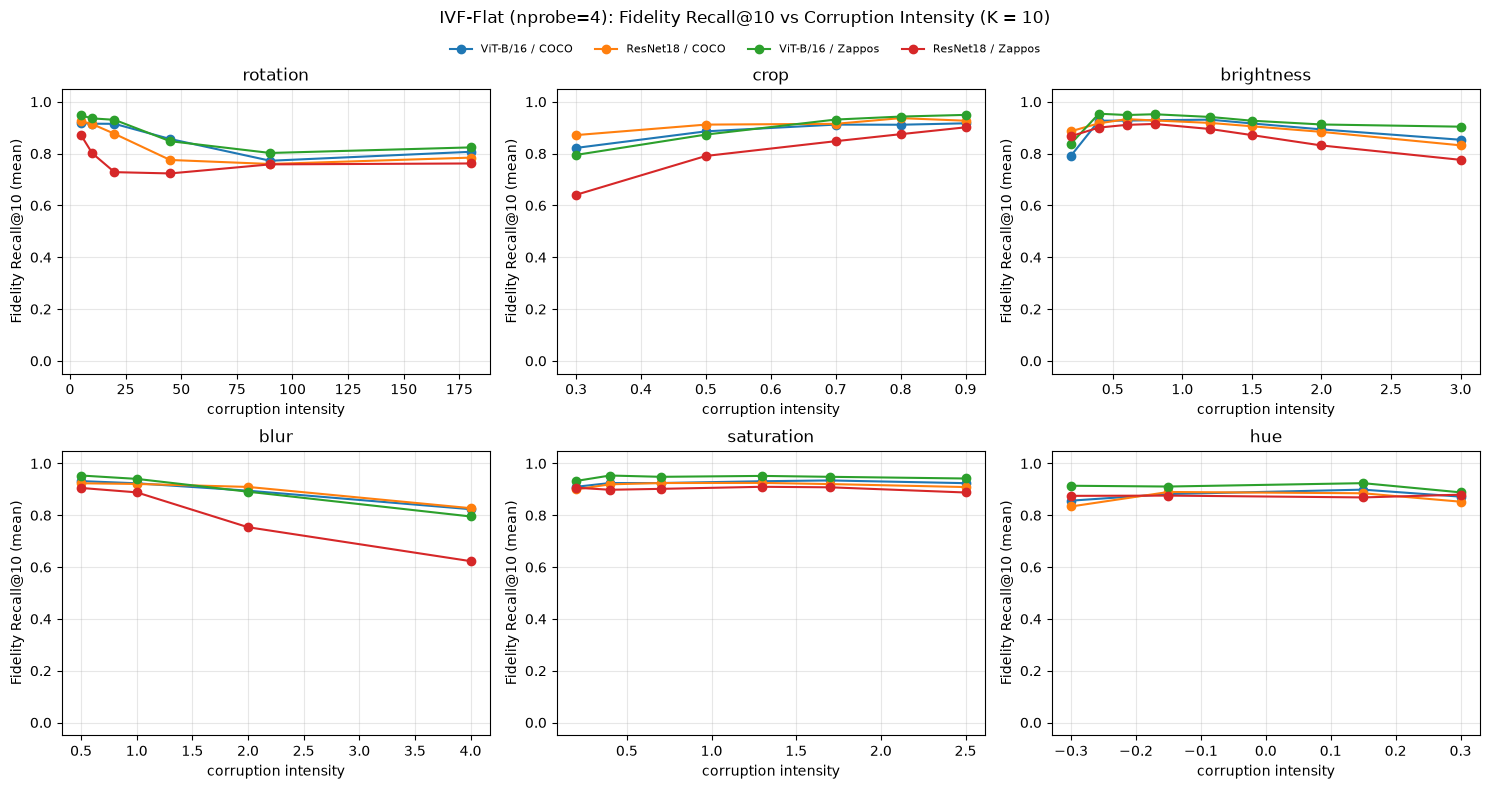

saved media\corruption_hnsw_fidelity_recall_at_10.png


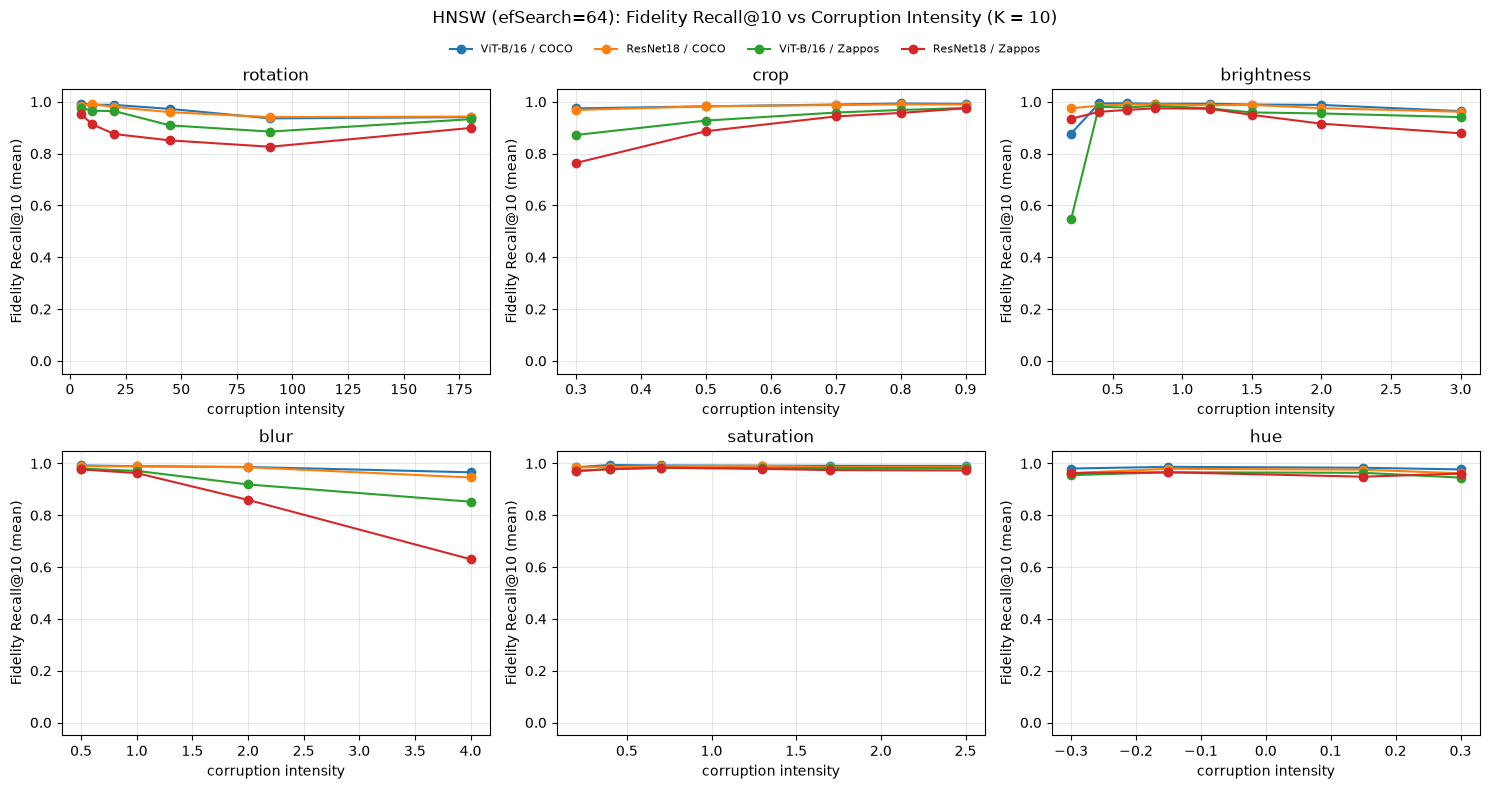

In [39]:
if ir_summary is not None:
    def corruption_curves(algorithm, column, ylabel, file_stem):
        """Exact-search figure format, one figure per index: one panel
        per transform, all four configurations as lines (colour = configuration)."""
        fig, axes = plt.subplots(2, 3, figsize=(15, 8))
        for ax, spec in zip(axes.ravel(), TRANSFORMS):
            transform = spec["name"]
            for k in IR_KEYS:
                sub = (ir_summary[(ir_summary["config"] == k)
                                  & (ir_summary["algorithm"] == algorithm)
                                  & (ir_summary["transform"] == transform)]
                       .sort_values("order"))
                ax.plot(sub["level"].astype(float), sub[column], marker="o",
                        color=CONFIG_COLORS[k], label=meta.loc[k, "label"])
            ax.set_title(transform)
            ax.set_xlabel("corruption intensity")
            ax.set_ylabel(ylabel)
            ax.set_ylim(-0.05, 1.05)
            ax.grid(alpha=0.3)
        setting = ir_summary[ir_summary["algorithm"] == algorithm]["setting"].iloc[0]
        fig.suptitle(f"{algorithm} ({setting}): {ylabel.removesuffix(' (mean)')} "
                     f"vs Corruption Intensity (K = {K_SHOW})")
        legend_above(fig, axes[0][0])
        save_figure(fig, file_stem)
        plt.show()

    for algorithm, stem in (("IVF-Flat", "ivfflat"), ("HNSW", "hnsw")):
        corruption_curves(algorithm, f"fidelity_recall_at_{K_SHOW}_mean",
                          f"Fidelity Recall@{K_SHOW} (mean)",
                          f"corruption_{stem}_fidelity_recall_at_{K_SHOW}")

**Fidelity Recall@10, ViT / Zappos**

saved media\corruption_vit-zappos_fidelity_recall_at_10.png


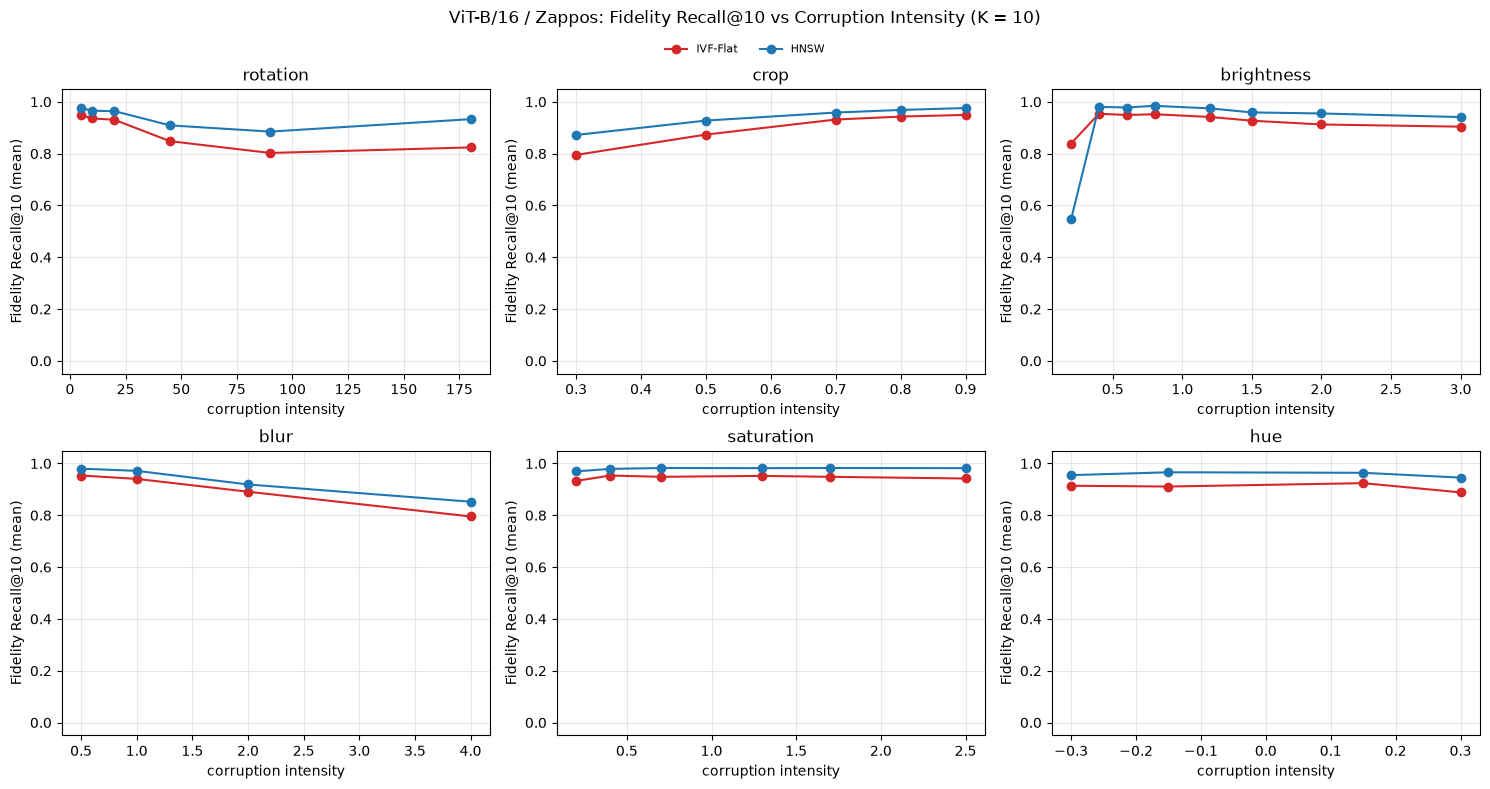

In [40]:
# One figure for a single configuration: IVF-Flat and HNSW as lines (the
# transposed view of corruption_curves above).
if ir_summary is not None:
    CONFIG_SHOW = "vit-zappos"   # the configuration highlighted here and below

    def config_curves(key, column, ylabel, file_stem):
        """One figure for a single configuration: one panel per transform,
        IVF-Flat and HNSW as lines (the transposed view of corruption_curves)."""
        fig, axes = plt.subplots(2, 3, figsize=(15, 8))
        for ax, spec in zip(axes.ravel(), TRANSFORMS):
            transform = spec["name"]
            for algorithm in IR_ALGORITHMS:
                sub = (ir_summary[(ir_summary["config"] == key)
                                  & (ir_summary["algorithm"] == algorithm)
                                  & (ir_summary["transform"] == transform)]
                       .sort_values("order"))
                ax.plot(sub["level"].astype(float), sub[column], marker="o",
                        color=METHOD_COLORS[algorithm], label=algorithm)
            ax.set_title(transform)
            ax.set_xlabel("corruption intensity")
            ax.set_ylabel(ylabel)
            ax.set_ylim(-0.05, 1.05)
            ax.grid(alpha=0.3)
        fig.suptitle(f"{meta.loc[key, 'label']}: {ylabel.removesuffix(' (mean)')} "
                     f"vs Corruption Intensity (K = {K_SHOW})")
        legend_above(fig, axes[0][0])
        save_figure(fig, file_stem)
        plt.show()

    config_curves(CONFIG_SHOW, f"fidelity_recall_at_{K_SHOW}_mean",
                  f"Fidelity Recall@{K_SHOW} (mean)",
                  f"corruption_{CONFIG_SHOW}_fidelity_recall_at_{K_SHOW}")

**Average Fidelity Recall@10** (over the 33 corrupted variants)

saved media\corruption_avg_fidelity_recall_at_10.png


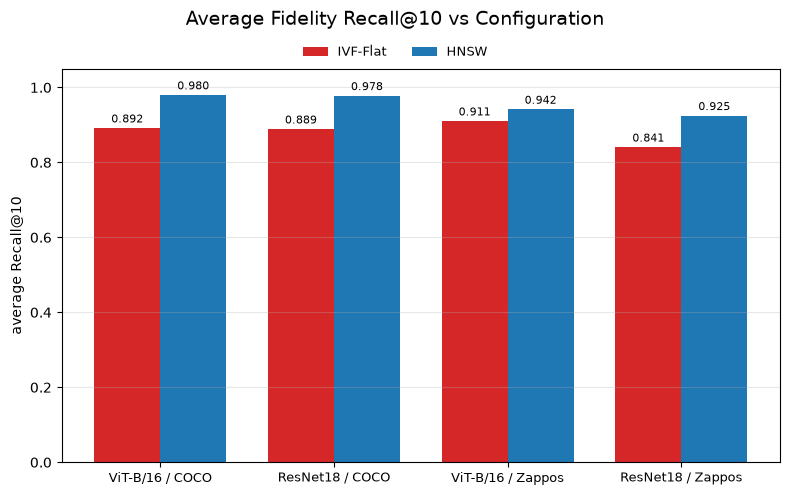

In [41]:
# One bar per (configuration, index), averaged over the corrupted variants.
if ir_summary is not None:
    def average_recall_bars(column, ylabel, title, file_stem):
        """One bar per (configuration, index), averaged over the corrupted variants."""
        corrupted = ir_summary[ir_summary["transform"] != "original"]
        means = corrupted.groupby(["config", "algorithm"])[column].mean()
        fig, ax = plt.subplots(figsize=(8, 5))
        width = 0.38
        xs = np.arange(len(IR_KEYS))
        for offset, algorithm in ((-width / 2, "IVF-Flat"), (width / 2, "HNSW")):
            values = [means.loc[(k, algorithm)] for k in IR_KEYS]
            bars = ax.bar(xs + offset, values, width,
                          color=METHOD_COLORS[algorithm], label=algorithm)
            ax.bar_label(bars, fmt="%.3f", fontsize=8, padding=2)
        ax.set_xticks(xs, [meta.loc[k, "label"] for k in IR_KEYS], fontsize=9)
        ax.set_ylabel(ylabel)
        ax.set_ylim(0, 1.05)
        ax.grid(alpha=0.3, axis="y")
        fig.suptitle(title, fontsize=14)
        legend_above(fig, ax, fontsize=9)
        save_figure(fig, file_stem)
        plt.show()

    average_recall_bars(f"fidelity_recall_at_{K_SHOW}_mean", "average Recall@10",
                        "Average Fidelity Recall@10 vs Configuration",
                        f"corruption_avg_fidelity_recall_at_{K_SHOW}")

saved media\corruption_ivfflat_end_to_end_recall_at_10.png


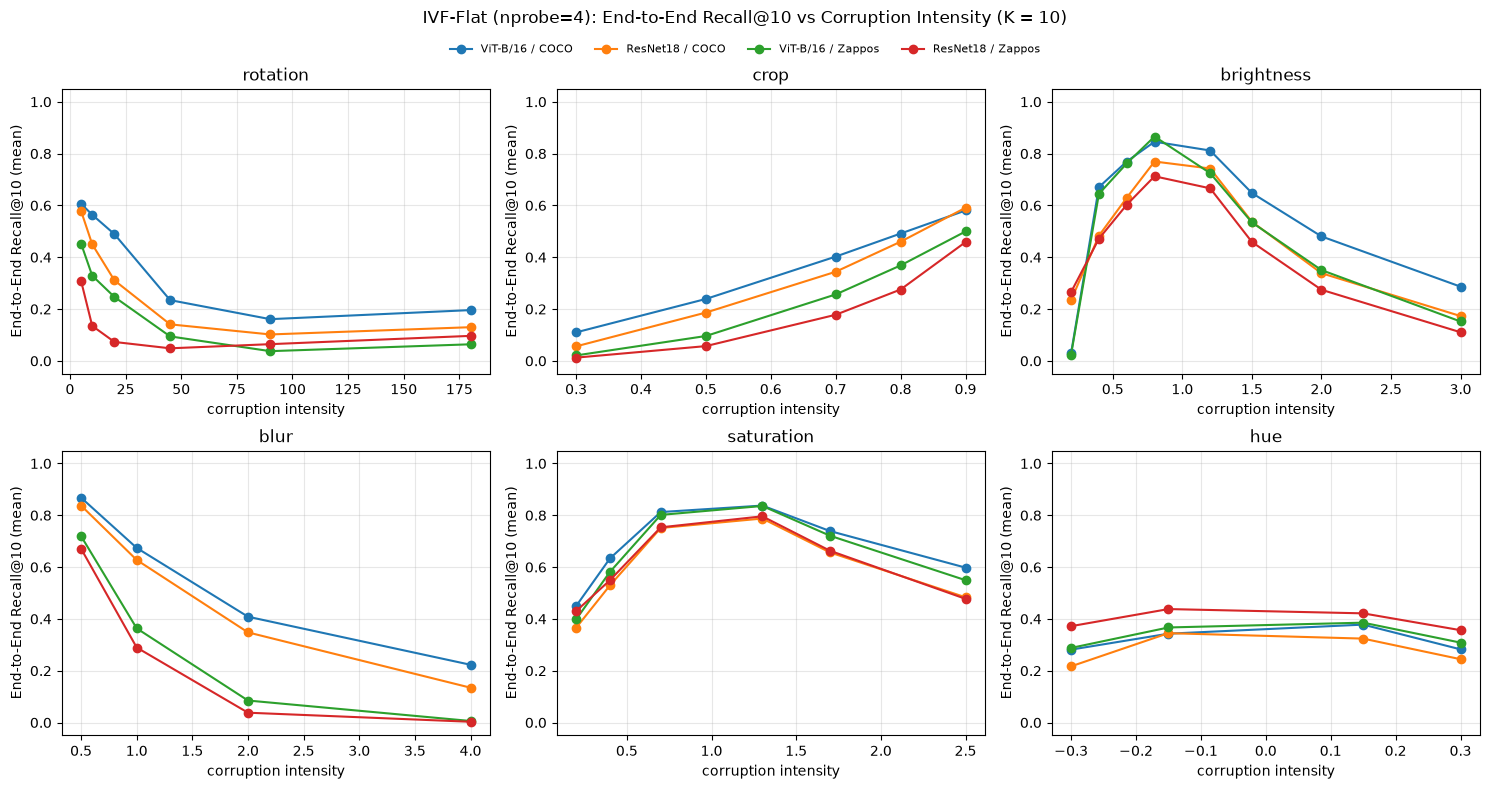

saved media\corruption_hnsw_end_to_end_recall_at_10.png


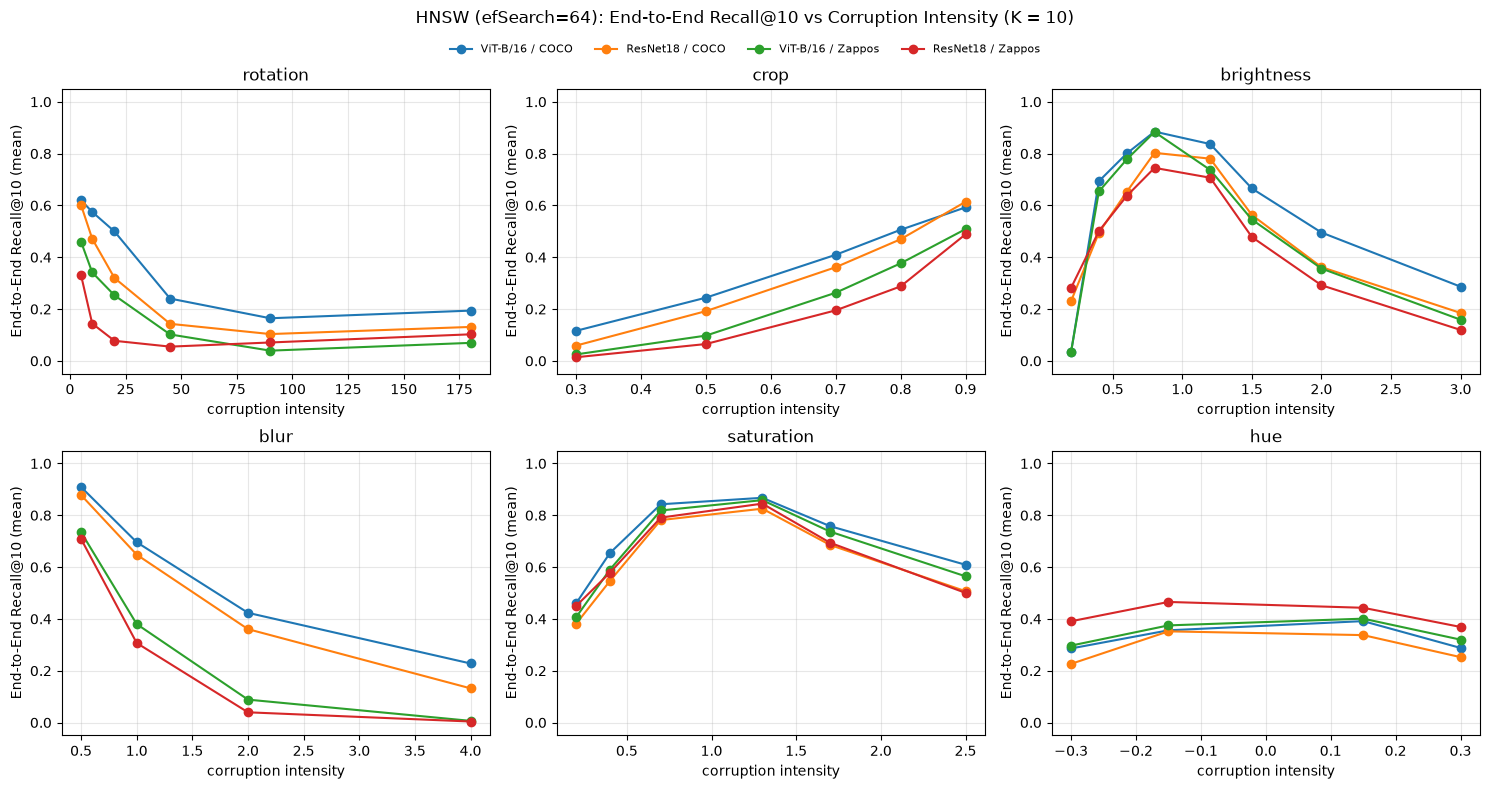

In [42]:
if ir_summary is not None:
    for algorithm, stem in (("IVF-Flat", "ivfflat"), ("HNSW", "hnsw")):
        corruption_curves(algorithm, f"end_to_end_recall_at_{K_SHOW}_mean",
                          f"End-to-End Recall@{K_SHOW} (mean)",
                          f"corruption_{stem}_end_to_end_recall_at_{K_SHOW}")

**End-to-End Recall@10, ViT / Zappos**

saved media\corruption_vit-zappos_end_to_end_recall_at_10.png


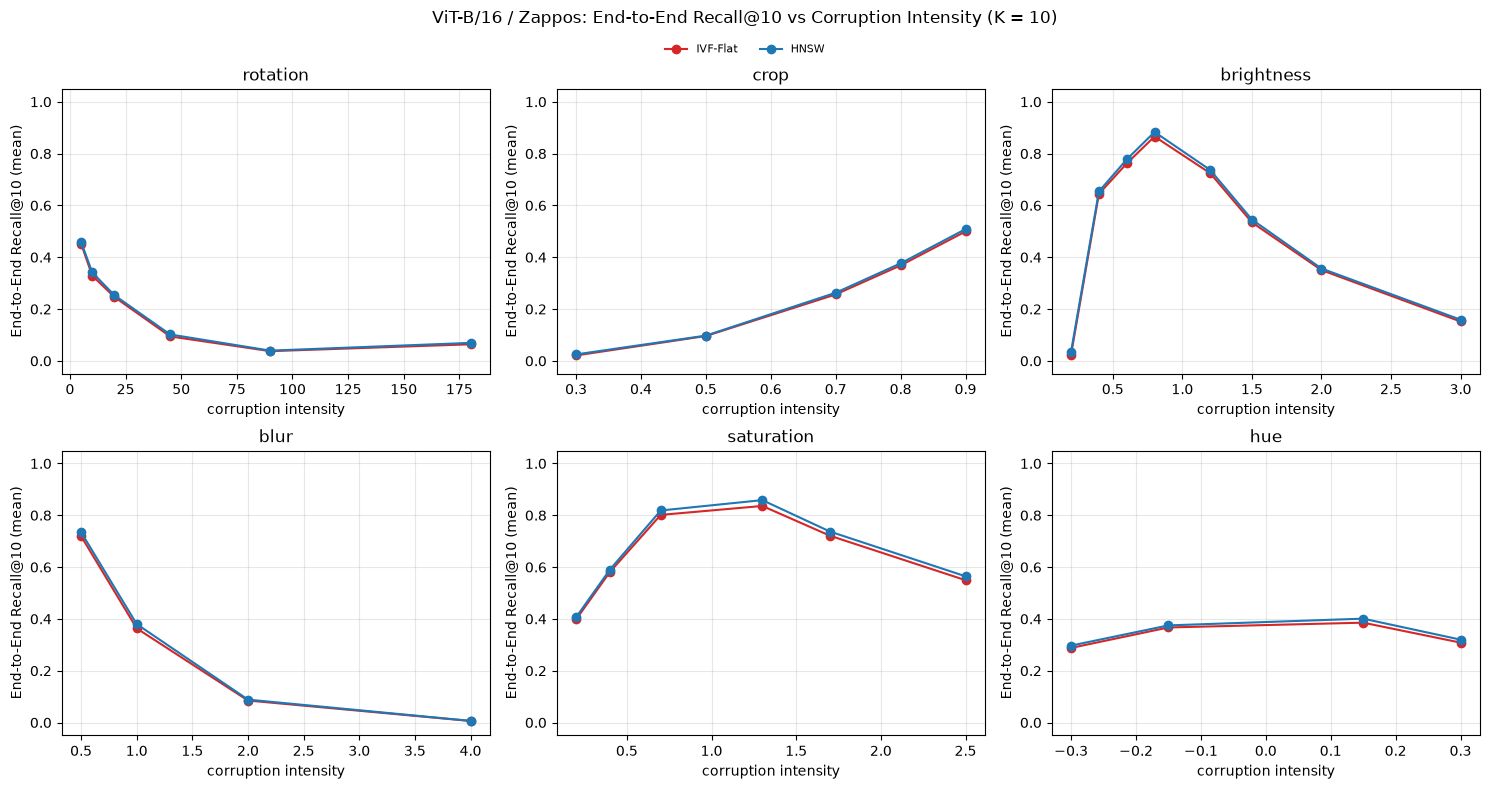

In [43]:
if ir_summary is not None:
    config_curves(CONFIG_SHOW, f"end_to_end_recall_at_{K_SHOW}_mean",
                  f"End-to-End Recall@{K_SHOW} (mean)",
                  f"corruption_{CONFIG_SHOW}_end_to_end_recall_at_{K_SHOW}")

**Average End-to-End Recall@10**

saved media\corruption_avg_end_to_end_recall_at_10.png


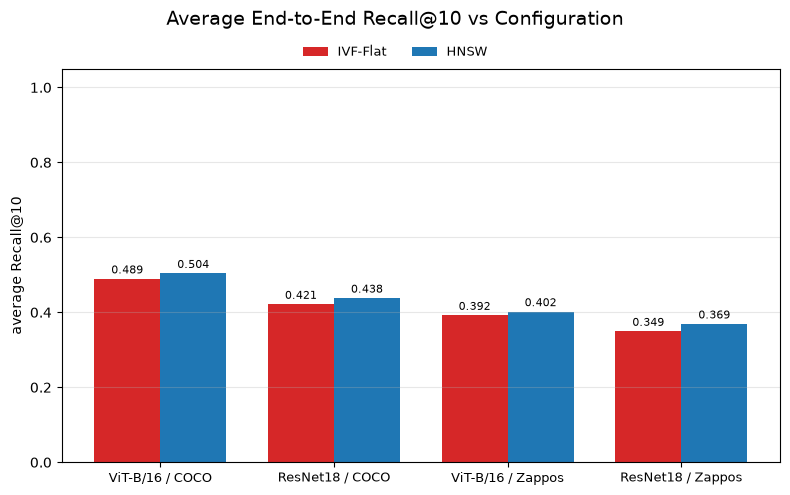

In [44]:
if ir_summary is not None:
    average_recall_bars(f"end_to_end_recall_at_{K_SHOW}_mean", "average Recall@10",
                        "Average End-to-End Recall@10 vs Configuration",
                        f"corruption_avg_end_to_end_recall_at_{K_SHOW}")

saved media\corruption_ivfflat_stability_recall_at_10.png


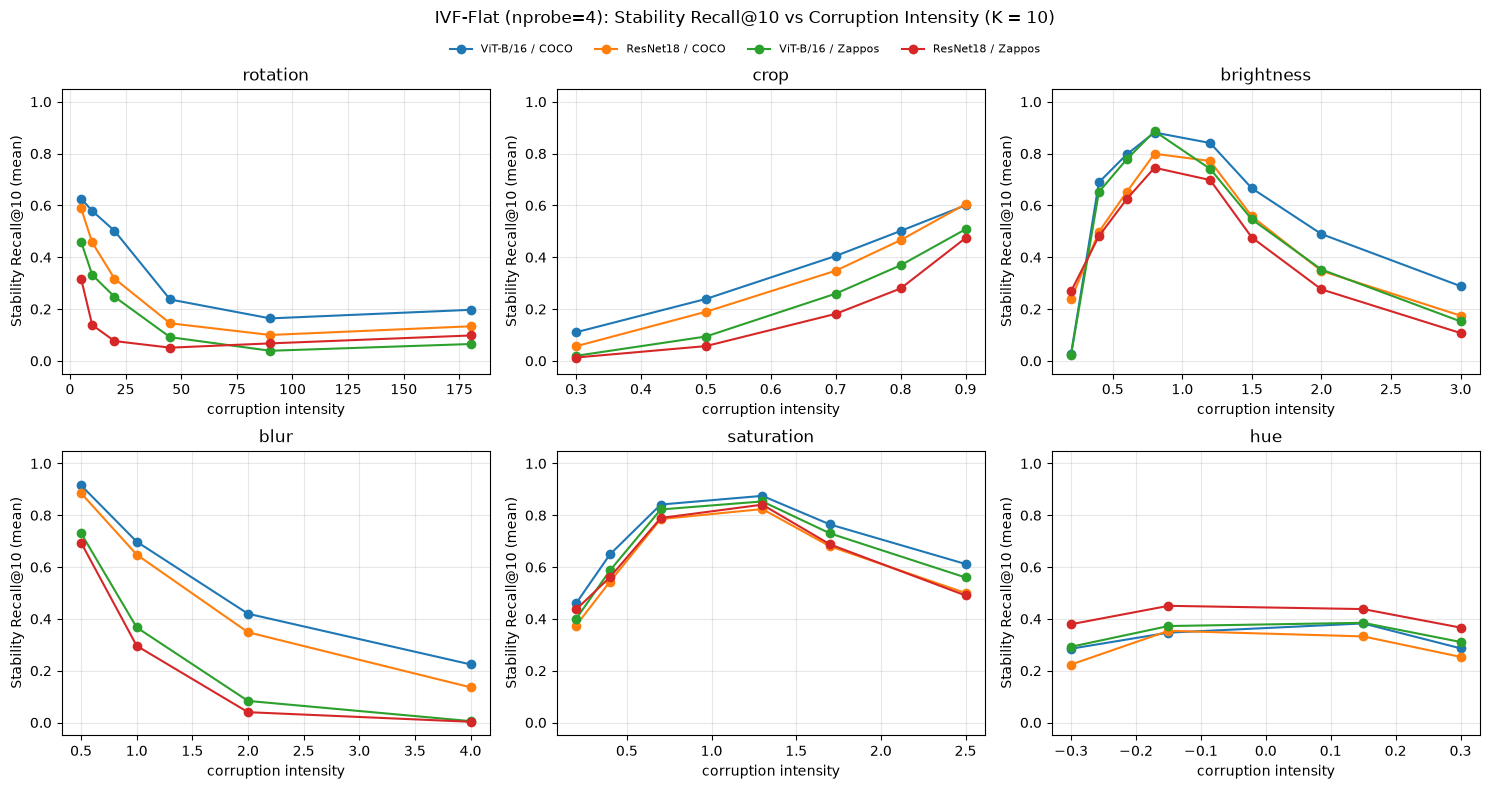

saved media\corruption_hnsw_stability_recall_at_10.png


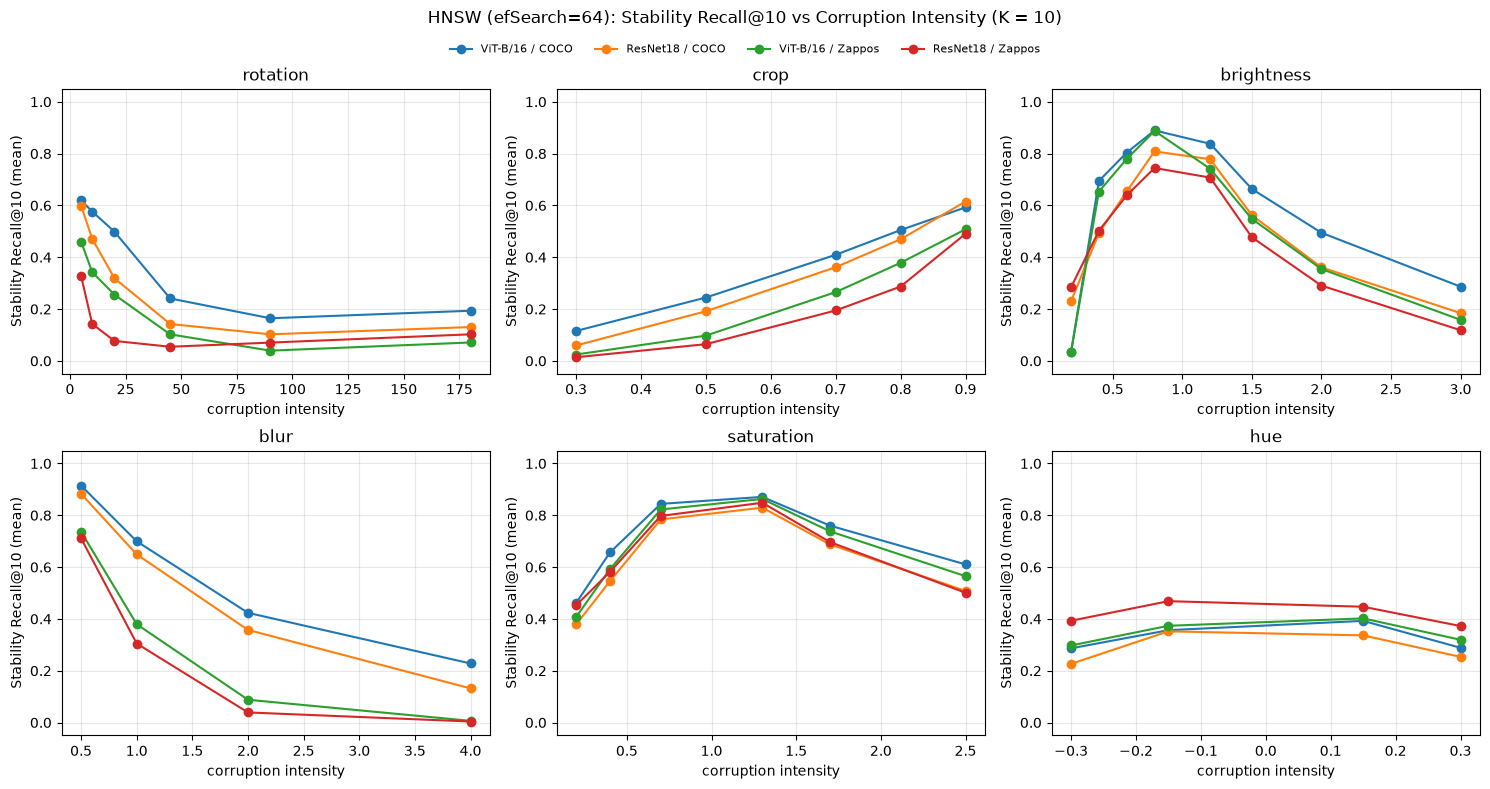

In [45]:
if ir_summary is not None:
    for algorithm, stem in (("IVF-Flat", "ivfflat"), ("HNSW", "hnsw")):
        corruption_curves(algorithm, f"stability_recall_at_{K_SHOW}_mean",
                          f"Stability Recall@{K_SHOW} (mean)",
                          f"corruption_{stem}_stability_recall_at_{K_SHOW}")

**Stability Recall@10, ViT / Zappos**

saved media\corruption_vit-zappos_stability_recall_at_10.png


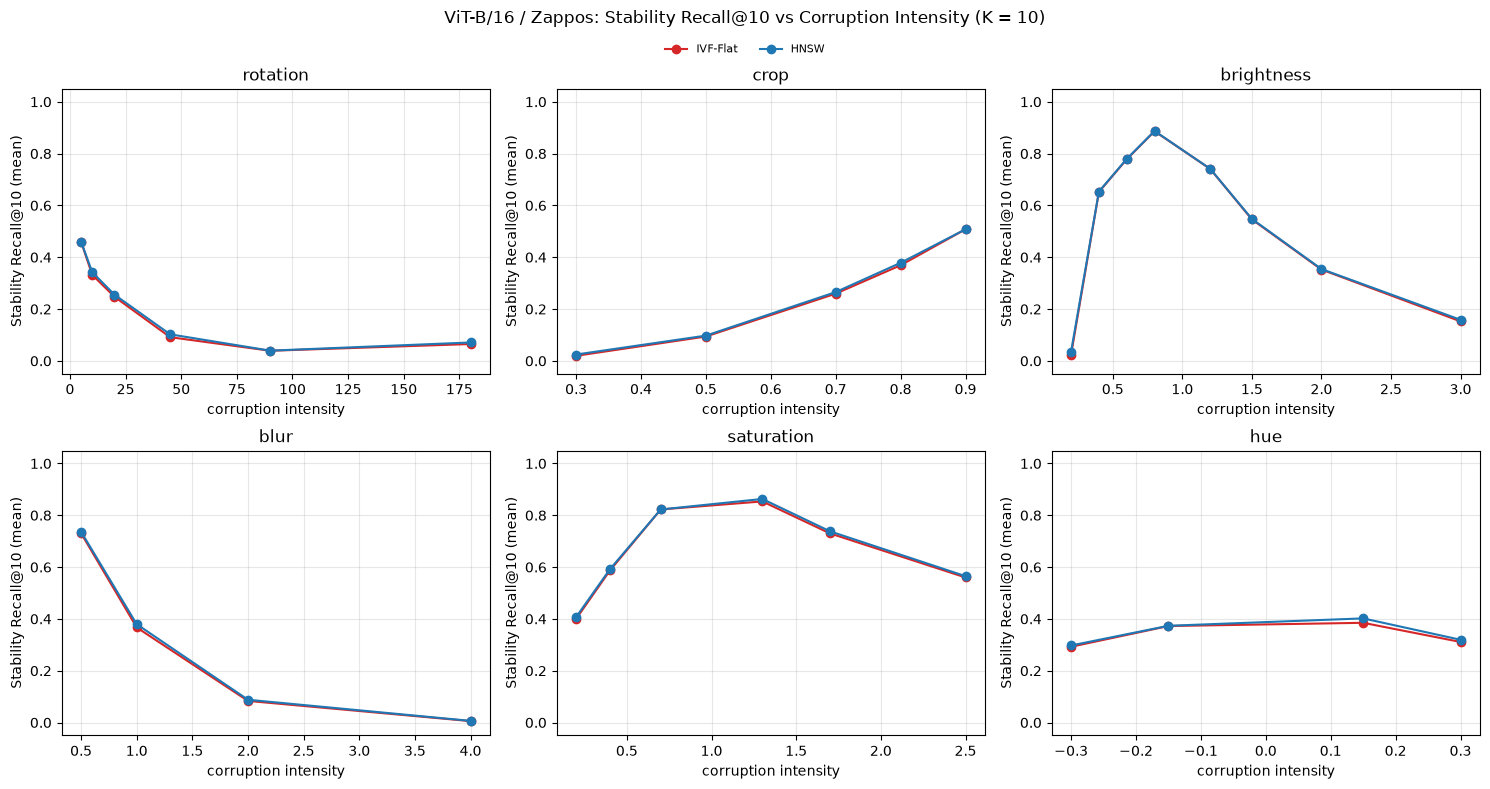

In [46]:
if ir_summary is not None:
    config_curves(CONFIG_SHOW, f"stability_recall_at_{K_SHOW}_mean",
                  f"Stability Recall@{K_SHOW} (mean)",
                  f"corruption_{CONFIG_SHOW}_stability_recall_at_{K_SHOW}")

**Average Stability Recall@10**

saved media\corruption_avg_stability_recall_at_10.png


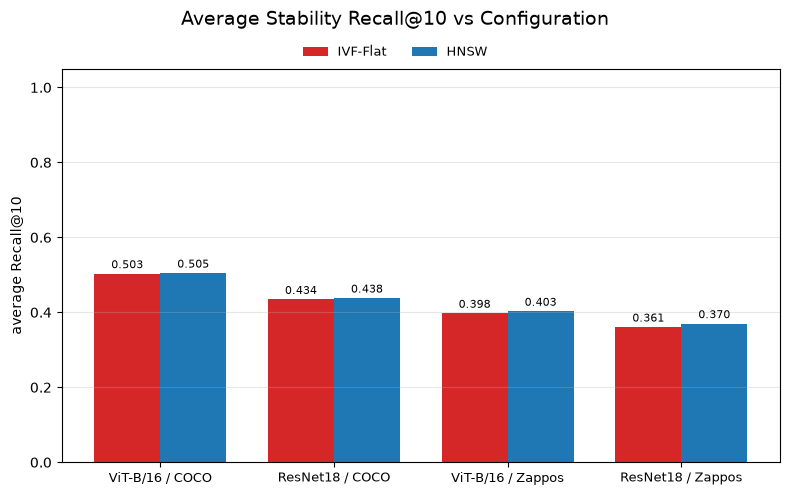

In [47]:
if ir_summary is not None:
    average_recall_bars(f"stability_recall_at_{K_SHOW}_mean", "average Recall@10",
                        "Average Stability Recall@10 vs Configuration",
                        f"corruption_avg_stability_recall_at_{K_SHOW}")

### Corrupted query and answers

The same queries corrupted (brightness for ViT, crop for ResNet18); `OK` / `MISS` vs the clean top-5.

In [48]:
# The corrupted twin of the Query-and-answers grid: same first query per
# dataset, one corruption per embedding model. Reuses K_ANSWERS / image_info
# from that cell; answers come from the corruption run's local cache and the
# corrupted query is rendered with pipeline/perturbations.py.
import csv
from perturbations import perturb   # TRANSFORMS is already imported above

ROW_CORRUPTIONS = {           # one corruption per embedding model
    "vit-coco": ("brightness", 0.4),
    "resnet-coco": ("crop", 0.7),
    "vit-zappos": ("brightness", 0.4),
    "resnet-zappos": ("crop", 0.7),
}

rows = []
for key, (transform, level) in ROW_CORRUPTIONS.items():
    dataset = CONFIGS[key]["dataset"]
    info = image_info[dataset]
    rob = results_dir(key) / "robustness"
    needed = ("corrupted_query_top20.npy", "corrupted_query_clean_top20.npy",
              "corrupted_query_variants.csv", "corrupted_query_embeddings.npy",
              "corruption_per_query.csv", "corruption_params.json")
    if info is None or not all((rob / name).exists() for name in needed):
        print(f"{meta.loc[key, 'label']}: skipped - needs the images and the local "
              f"corruption cache (re-run pipeline/corruption.py)")
        continue
    # The gallery mapping, reproduced exactly as pipeline/corruption.py built it.
    bench = json.loads((results_dir(key) / "ann_results.json").read_text())["metadata"]
    gallery_rows = np.sort(np.random.default_rng(bench["seed"])
                           .permutation(bench["dataset_size"])[bench["num_queries"]:])
    ids = np.load(CONFIGS[key]["ids"])
    embeddings = np.load(CONFIGS[key]["emb"], mmap_mode="r")

    params = json.loads((rob / "corruption_params.json").read_text())
    query_row = int(params["query_rows"][0])   # the same first query as the clean grid
    query_id = int(ids[query_row])

    # Position of (query 0, transform, level) in the cached arrays.
    variants = list(csv.DictReader((rob / "corrupted_query_variants.csv").open()))
    position = next(i for i, v in enumerate(variants)
                    if int(v["query"]) == 0 and v["transform"] == transform
                    and float(v["level"]) == float(level))
    metrics = next(r for r in csv.DictReader((rob / "corruption_per_query.csv").open())
                   if int(r["query"]) == 0 and r["transform"] == transform
                   and float(r["level"]) == float(level))

    corrupted_top20 = np.load(rob / "corrupted_query_top20.npy")
    clean_top20 = np.load(rob / "corrupted_query_clean_top20.npy")
    query_vector = np.load(rob / "corrupted_query_embeddings.npy")[position]

    # OK/MISS against the clean query's top-5 (the answers of the clean grid).
    reference = {int(ids[gallery_rows[int(g)]]) for g in clean_top20[0, :K_ANSWERS]}
    answers = []
    for gallery_row in corrupted_top20[position, :K_ANSWERS]:
        answer_id = int(ids[gallery_rows[int(gallery_row)]])
        vector = np.asarray(embeddings[int(gallery_rows[int(gallery_row)])])
        answers.append({"id": answer_id, "hit": answer_id in reference,
                        "score": float(query_vector @ vector)})
    rows.append({"key": key, "transform": transform, "level": level,
                 "query_id": query_id, "metrics": metrics, "answers": answers})

if not rows:
    print("Corrupted-query grid skipped: no configuration has the images and a "
          "local corruption cache.")
else:
    fig, axes = plt.subplots(len(rows), K_ANSWERS + 1,
                             figsize=(2.4 * (K_ANSWERS + 1), 3.0 * len(rows)))
    for r, row in enumerate(rows):
        key = row["key"]
        info = image_info[CONFIGS[key]["dataset"]]
        with Image.open(info["path"](row["query_id"])) as handle:
            sample = handle.convert("RGB")
        ax = axes[r][0]
        ax.imshow(perturb(sample, row["transform"], row["level"]))
        ax.set_title(f"{meta.loc[key, 'label']}\n{row['transform']} {row['level']:g} | "
                     f"cos {float(row['metrics']['cosine']):.2f} | "
                     f"R@10 {float(row['metrics']['recall_at_10']):.2f}", fontsize=8)
        ax.axis("off")
        for c, answer in enumerate(row["answers"]):
            ax = axes[r][c + 1]
            ax.imshow(Image.open(info["path"](answer["id"])).convert("RGB"))
            title = f"#{c + 1} {'OK' if answer['hit'] else 'MISS'}  cos {answer['score']:.3f}"
            label = info["label"](answer["id"])
            if label:
                title += f"\n{label}"
            title += f"\nid {answer['id']}"
            ax.set_title(title, fontsize=7, color="black" if answer["hit"] else "red")
            ax.axis("off")
    fig.suptitle("Corrupted query and its exact top-5 answers: one corruption per embedding model")
    fig.tight_layout()
    save_figure(fig, "corruption_query_answers_grid")
    plt.show()

ViT-B/16 / COCO: skipped - needs the images and the local corruption cache (re-run pipeline/corruption.py)
ResNet18 / COCO: skipped - needs the images and the local corruption cache (re-run pipeline/corruption.py)
ViT-B/16 / Zappos: skipped - needs the images and the local corruption cache (re-run pipeline/corruption.py)
ResNet18 / Zappos: skipped - needs the images and the local corruption cache (re-run pipeline/corruption.py)
Corrupted-query grid skipped: no configuration has the images and a local corruption cache.
